# **Análisis descriptivo - Población proyectada incluida**

**Periodos de estudio:**
1.   Población Objetivo: 2010 - 2024
2.   Población Estudio: 2016 - 2024


<br>
<br>
...............................................................................................................................................................................................................................................
<br>
<br>

# 💾 **Setup**
<br>








### Cargar información



In [1]:
# Importar liberías
  ## Manejo de base y estadísticas
import numpy as np
import pandas as pd


  ## Gráficas
import matplotlib.pyplot as plt
import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib.ticker import FuncFormatter

# Ruta
path_dw='../1 Data multidimensional/'
path_proyecciones = '../3 Proyecciones/'


In [2]:
# Dimensiones

  ## Edad
edad = pd.read_parquet(path_dw + 'DIM_EDAD.parquet')

  ## Población
pob = pd.read_parquet(path_dw + 'DW_POBLACION_COMUNAS.parquet')

  ## Comunas
comuna = pd.read_parquet(path_dw + 'DIM_COMUNAS.parquet')

  ## Registros afiliación a Sistema de salud
df=pd.read_parquet(path_proyecciones + 'Proyección_2010_2024.parquet')


In [3]:
# Ajuste Base Población

  ## Cruce y agrupación
pob=(pob[pob['Año'].isin(range(2010,2025))][['Sexo','Edad','Comuna','Año','Poblacion']].
     merge(edad[['Edad','RangoEdad10']], on='Edad', how='left').
     groupby(['Año','Comuna','Sexo','RangoEdad10'])['Poblacion'].sum().reset_index().
     merge(comuna[['Comuna','Region']], on='Comuna', how='left'))
pob=pob[['Año','Region','Comuna','Sexo','RangoEdad10','Poblacion']]


<br>
<br>
...............................................................................................................................................................................................................................................
<br>
<br>

## **Población Nacional**



### Población total y media por periodo de estudio

In [12]:
# Suma de beneficiarios totales y media por periodo de estudio
  ## Creación de DataFrame
pob_pe = pd.DataFrame({'Periodo_estudio': ['Objetivo','Estudio','Objetivo','Estudio'],
                       'Poblacion': [pob['Poblacion'].sum(),
                                     pob[pob['Año'].isin(range(2016,2025))]['Poblacion'].sum(),
                                     pob.groupby(['Año'])['Poblacion'].sum().rename('Poblacion').reset_index()['Poblacion'].mean(),
                                     pob[pob['Año'].isin(range(2016,2025))].groupby(['Año'])['Poblacion'].sum().rename('Poblacion').reset_index()['Poblacion'].mean()],
                       'Variable':['Población Total','Población Total','Población media anual','Población media anual']})

<br>

### Ditribución procentual variables demográficas por periodo de estudio



In [15]:
pob_sexo_pe = pd.concat([
    pob.groupby('Sexo')['Poblacion'].sum().rename('Pob_sexo').reset_index().assign(Periodo_estudio='Objetivo'),
    pob[pob['Año'].isin(range(2016, 2025))].groupby('Sexo')['Poblacion'].sum().rename('Pob_sexo').reset_index().assign(Periodo_estudio='Estudio')])
pob_sexo_pe

,Sexo,Pob_sexo,Periodo_estudio
0,1,137276831,Objetivo
1,2,141313150,Objetivo
0,1,85535879,Estudio
1,2,87921583,Estudio


In [17]:

# % Sexo

  ## Obtener total por periodo de estudio y sexo
pob_sexo_pe = pd.concat([
    pob.groupby('Sexo')['Poblacion'].sum().rename('Pob_sexo').reset_index().assign(Periodo_estudio='Objetivo'),
    pob[pob['Año'].isin(range(2016, 2025))].groupby('Sexo')['Poblacion'].sum().rename('Pob_sexo').reset_index().assign(Periodo_estudio='Estudio')])

  ## Calcular %
pob_sexo_pe=pob_sexo_pe.merge(pob_pe[pob_pe['Variable']=="Población Total"], on='Periodo_estudio', how='left')
pob_sexo_pe['%']=((pob_sexo_pe['Pob_sexo']/pob_sexo_pe['Poblacion'])*100).round(2)

  ## Ajustar estética
pob_sexo_pe=pob_sexo_pe.pivot(index='Sexo', columns='Periodo_estudio', values='%').reset_index()
pob_sexo_pe['Sexo']=pob_sexo_pe['Sexo'].map({1:'Mujer',2:'Hombre'})
pob_sexo_pe=pob_sexo_pe.rename(columns={'Sexo':'Categoría'})
pob_sexo_pe.columns.name = None
pob_sexo_pe['Variable']="Sexo"

In [19]:
# % rango etario

  ## Obtener total por periodo de estudio y edad
pob_edad_pe = pd.concat([pob.groupby(['RangoEdad10'])['Poblacion'].sum().rename('Pob_edad').reset_index().assign(Periodo_estudio='Objetivo'),
                         pob[pob['Año'].isin(range(2016, 2025))].groupby(['RangoEdad10'])['Poblacion'].sum().rename('Pob_edad').reset_index().assign(Periodo_estudio='Estudio')])
  ## Calcular %
pob_edad_pe=pob_edad_pe.merge(pob_pe[pob_pe['Variable']=="Población Total"], on='Periodo_estudio', how='left')
pob_edad_pe['%']=((pob_edad_pe['Pob_edad']/pob_edad_pe['Poblacion'])*100).round(2)

  ## Ajustar estética

pob_edad_pe=pob_edad_pe.pivot(index='RangoEdad10', columns='Periodo_estudio', values='%').reset_index()
pob_edad_pe=pob_edad_pe.rename(columns={'RangoEdad10':'Categoría'})
pob_edad_pe.columns.name = None
pob_edad_pe['Variable']="Rango Etario"

In [21]:
# Tabla 1.1
  ## Reordenar
Tabla_11=pob_pe.pivot(index='Variable', columns='Periodo_estudio', values='Poblacion').reset_index()
Tabla_11.columns.name = None
Tabla_11['Categoría']=""
Tabla_11=Tabla_11[['Variable','Categoría','Estudio','Objetivo']]

  ## Estética
Tabla_11.rename(columns={'Objetivo':'Población Objetivo','Estudio':'Población Estudio'}, inplace=True)
Tabla_11=Tabla_11.style.format({'Población Objetivo': '{:,.0f}', 'Población Estudio': '{:,.0f}'})


# Tabla 1.2
  ## Reordear
Tabla_12=pd.concat([pob_sexo_pe,pob_edad_pe])[['Variable','Categoría','Objetivo','Estudio']]

  ## Estética
Tabla_12=Tabla_12.round(2)
Tabla_12.columns.name = None
Tabla_12.rename(columns={'Objetivo':'Población Objetivo %','Estudio':'Población Estudio %'}, inplace=True)

# Visualización
display(Tabla_11)
display(Tabla_12)

,Variable,Categoría,Población Estudio,Población Objetivo
0,Población Total,,"173,457,462","278,589,981"
1,Población media anual,,"19,273,051","18,572,665"


,Variable,Categoría,Población Objetivo %,Población Estudio %
0,Sexo,Mujer,49.28,49.31
1,Sexo,Hombre,50.72,50.69
0,Rango Etario,"[0, 10)",13.23,12.76
1,Rango Etario,"[10, 20)",13.90,13.08
2,Rango Etario,"[20, 30)",15.78,15.50
3,Rango Etario,"[30, 40)",15.21,15.51
4,Rango Etario,"[40, 50)",13.67,13.57
5,Rango Etario,"[50, 60)",11.99,12.18
6,Rango Etario,"[60, 70)",8.65,9.29
7,Rango Etario,"[70, 80)",4.91,5.25


In [25]:
pob_graf=pob.groupby(['Año','Sexo','RangoEdad10'])['Poblacion'].sum().rename('Poblacion').reset_index()
pob_graf['Sexo'] = pob_graf['Sexo'].map({1: 'Mujer', 2: 'Hombre'})

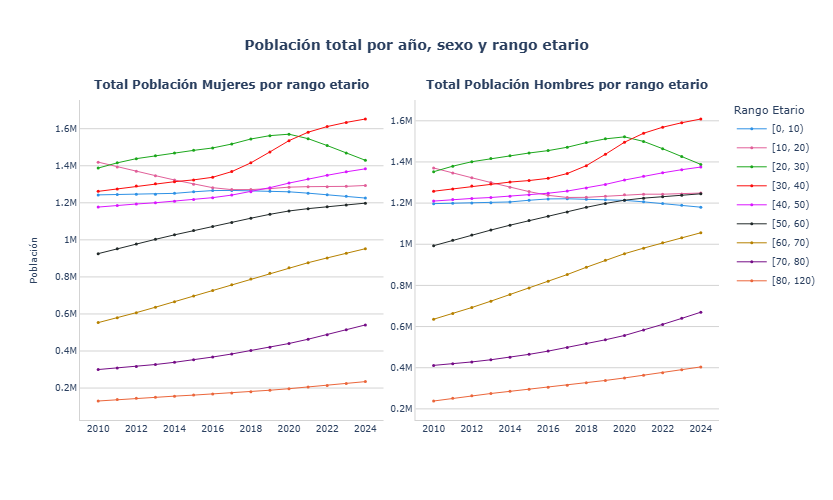

In [27]:
# New graph generation using pob_graf

rango_edad_unique = sorted(pob_graf['RangoEdad10'].unique())
colors_rango_edad_palette = px.colors.qualitative.Dark24
color_map_rango_edad = {rango: colors_rango_edad_palette[i % len(colors_rango_edad_palette)] for i, rango in enumerate(rango_edad_unique)}

paneles = [
    {"sexo": "Mujer",
     "col": 1, "titulo":
     "Total Población Mujeres por rango etario"},
    {"sexo": "Hombre",
     "col": 2,
     "titulo": "Total Población Hombres por rango etario"}]

# Subplots
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[p["titulo"] for p in paneles],
    horizontal_spacing=0.05)

# graficos
for p in paneles:
    df_sexo = pob_graf[pob_graf["Sexo"] == p["sexo"]]

    for rango_edad in rango_edad_unique:
        datos = df_sexo[df_sexo["RangoEdad10"] == rango_edad].copy()

        fig.add_trace(
            go.Scatter(
                x=datos["Año"],
                y=datos["Poblacion"],
                mode="lines+markers",
                name=f"{rango_edad}",
                legendgroup=p["sexo"],
                showlegend=True if p["col"] == 1 else False,
                line=dict(color=color_map_rango_edad[rango_edad], width=1),
                marker=dict(color=color_map_rango_edad[rango_edad], size=3)),
            row=1,
            col=p["col"])

# Update Layout
fig.update_layout(
    title_text='Población total por año, sexo y rango etario',
    title_font=dict(size=14, weight='bold'),
    title_x=0.5,
    height=500,
    width=1200,
    plot_bgcolor="white",
    paper_bgcolor="white",
    hovermode='x unified',
    legend=dict(
        orientation="v",
        yanchor="top",
        y=1,
        xanchor="left",
        x=1.02,
        title_text="Rango Etario",
        font=dict(size=9)))

fig.update_annotations(y=1.02, font=dict(size=12, weight='bold'))

for col_idx in range(1, 3):
    fig.update_xaxes(
        showline=True, linewidth=1, linecolor="lightgray",
        row=1, col=col_idx, tickfont=dict(size=9),
        dtick=2)
    fig.update_yaxes(showline=True, linewidth=1, linecolor="lightgray",showgrid=True, gridcolor="LightGrey",
        row=1, col=col_idx, tickfont=dict(size=9), title_font=dict(size=10))

fig.update_yaxes(title_text="Población", col=1)

fig.show()

<br>
<br>
...............................................................................................................................................................................................................................................
<br>
<br>

## **Cobertura sistema de salud - general**

<br>

### Distribución cobertura por año

In [31]:

# Cálculo de cobertura por año

  ## Total tramo anual
df_año_tramo=df.groupby(['Año','Tramo'])['Beneficiarios'].sum().rename('Benef_tramo').reset_index()


  ## % de cobertura por año
df_año_tramo=df_año_tramo.merge(pob.groupby(['Año'])['Poblacion'].sum().rename('Poblacion').reset_index(), on=['Año'], how='left')
df_año_tramo['%']=((df_año_tramo['Benef_tramo']/df_año_tramo['Poblacion'])*100).round(2)

  ## % de diferencia
df_año_tramo=df_año_tramo.pivot(index=['Año','Poblacion'], columns='Tramo', values='%').fillna(0).reset_index()
df_año_tramo['Cobertura N/I (%)']=100-df_año_tramo['Isapre']-df_año_tramo['Tramo A']-df_año_tramo['Tramo B']-df_año_tramo['Tramo C']-df_año_tramo['Tramo D']
df_año_tramo.columns.name = None



In [33]:
# Cálculo de cobertura por periodo de estudio

  ## Beneficiarios por periodo de estudio
df_tramo_pe=pd.concat([df.groupby(['Tramo'])['Beneficiarios'].sum().rename('Benef_tramo').reset_index().assign(Periodo_estudio='Objetivo'),
                       df[df['Año'].isin(range(2016,2025))].groupby(['Tramo'])['Beneficiarios'].sum().rename('Benef_tramo').reset_index().assign(Periodo_estudio='Estudio')])

  ## % cobertura por periodo de estudio
df_tramo=df_tramo_pe.merge(pob_pe[pob_pe['Variable']=="Población Total"], on='Periodo_estudio', how='left')
df_tramo['%']=((df_tramo['Benef_tramo']/df_tramo['Poblacion'])*100).round(2)
df_tramo=df_tramo.pivot(index=['Periodo_estudio','Poblacion'], columns='Tramo', values='%').fillna(0).reset_index()
df_tramo['Cobertura N/I (%)']=100-df_tramo['Isapre']-df_tramo['Tramo A']-df_tramo['Tramo B']-df_tramo['Tramo C']-df_tramo['Tramo D']
df_tramo.columns.name = None

In [35]:
# Tabla

  ## Ajustar estética

columnas = ["Tramo A", "Tramo B", "Tramo C", "Tramo D", "Isapre"]

Tabla_21 = df_tramo.rename(columns={col: f"{col} (%)" for col in columnas})
Tabla_22 = df_año_tramo.rename(columns={col: f"{col} (%)" for col in columnas})

Tabla_21=Tabla_21.style.format({'Poblacion': '{:,.0f}', 'Isapre (%)': '{:,.2f}', 'Tramo A (%)': '{:,.2f}', 'Tramo B (%)': '{:,.2f}', 'Tramo C (%)': '{:,.2f}', 'Tramo D (%)': '{:,.2f}', 'Cobertura N/I (%)': '{:,.2f}'})
Tabla_22=Tabla_22.style.format({'Poblacion': '{:,.0f}', 'Isapre (%)': '{:,.2f}', 'Tramo A (%)': '{:,.2f}', 'Tramo B (%)': '{:,.2f}', 'Tramo C (%)': '{:,.2f}', 'Tramo D (%)': '{:,.2f}', 'Cobertura N/I (%)': '{:,.2f}'})

display(Tabla_21)
display(Tabla_22)

,Periodo_estudio,Poblacion,Isapre (%),Tramo A (%),Tramo B (%),Tramo C (%),Tramo D (%),Cobertura N/I (%)
0,Estudio,"173,457,462",16.66,16.28,28.88,12.64,19.24,6.30
1,Objetivo,"278,589,981",16.51,16.13,28.62,12.53,19.07,7.14


,Año,Poblacion,Isapre (%),Tramo A (%),Tramo B (%),Tramo C (%),Tramo D (%),Cobertura N/I (%)
0,2010,"17,063,927",16.13,15.76,27.96,12.24,18.63,9.28
1,2011,"17,254,159",16.18,15.81,28.05,12.28,18.69,8.99
2,2012,"17,443,491",16.23,15.87,28.14,12.32,18.75,8.69
3,2013,"17,611,902",16.29,15.92,28.23,12.36,18.81,8.39
4,2014,"17,787,617",16.34,15.97,28.32,12.40,18.88,8.09
5,2015,"17,971,423",16.39,16.02,28.41,12.44,18.94,7.80
6,2016,"18,167,147",18.86,17.48,24.60,11.36,20.03,7.67
7,2017,"18,419,192",18.42,18.08,24.59,13.80,18.27,6.84
8,2018,"18,751,405",18.16,17.64,26.07,11.96,18.44,7.73
9,2019,"19,107,216",17.96,16.96,27.12,12.41,20.06,5.49


<br>

### Visualización Serie de Tiempo - sistema de salud

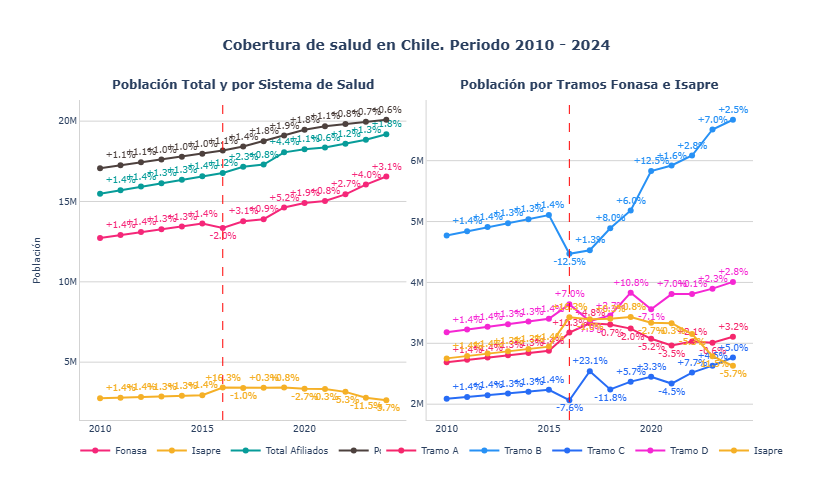

In [38]:
# Agregación y ajuste base

df_graf=df.pivot_table(index='Año', columns='Tramo', values='Beneficiarios', aggfunc='sum').fillna(0).reset_index()
df_graf['Fonasa']=df_graf[['Tramo A', 'Tramo B', 'Tramo C', 'Tramo D']].sum(axis=1)
df_graf['Total Afiliados']=df_graf['Fonasa']+df_graf['Isapre']
df_graf=df_graf.merge(pob.groupby(['Año'])['Poblacion'].sum().rename('Poblacion').reset_index(), on=['Año'], how='left')


df_graf=df_graf.melt(id_vars='Año', value_vars=["Tramo A", "Tramo B", "Tramo C", "Tramo D",'Isapre', 'Fonasa', 'Total Afiliados','Poblacion'],
    var_name='Afiliacion',value_name='Total')

# Cálculo variación porcentual
df_graf["Variacion"] = (df_graf.groupby("Afiliacion")["Total"].pct_change().fillna(0))
df_graf["Variacion_pct"] = (df_graf["Variacion"] * 100).round(2)


# Gráfica

  ## Colores

sistema_colores = {
    "Fonasa": "#F52779",
    "Isapre": "#F5B027",
    "Total Afiliados": "#079C99",
    "Poblacion":"#4D413E"}

tramo_colores = {
    "Tramo A": "#F5276C",
    "Tramo B": "#2791F5",
    "Tramo C": "#276CF5",
    "Tramo D": "#F527D3",
    "Isapre": "#F5B027"}

  ## Configuración

paneles = [
    {"col": 1,
     "titulo": "Población Total y por Sistema de Salud",
     "categorias": ["Fonasa", "Isapre", "Total Afiliados","Poblacion"],
     "colores": sistema_colores,
     "legend": "legend",},

    {"col": 2,
     "titulo": "Población por Tramos Fonasa e Isapre",
     "categorias": ["Tramo A", "Tramo B", "Tramo C", "Tramo D", "Isapre"],
     "colores": tramo_colores,
     "legend": "legend2",}]

  ## Subplots

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=[p["titulo"] for p in paneles],
    horizontal_spacing=0.03)

  ## graficos

for p in paneles:
    df_panel = df_graf[df_graf["Afiliacion"].isin(p["categorias"])]

    for categoria in p["categorias"]:
        datos = df_panel[df_panel["Afiliacion"] == categoria].copy()

        datos["Etiqueta_pct"] = datos["Variacion_pct"].apply(
            lambda x: f"{x:+.1f}%" if x != 0 else "")

        datos["Posicion_texto"] = datos["Variacion_pct"].apply(
            lambda x: "top center" if x >= 0 else "bottom center")

        fig.add_trace(
            go.Scatter(
                x=datos["Año"],
                y=datos["Total"],
                mode="lines+markers+text",
                name=categoria,
                legend=p["legend"],
                line=dict(color=p["colores"][categoria]),
                marker=dict(color=p["colores"][categoria]),
                text=datos["Etiqueta_pct"],
                textposition=datos["Posicion_texto"],
                textfont=dict(
                    size=8.5,
                    color=p["colores"][categoria]),
                customdata=datos["Variacion_pct"]),
            row=1,
            col=p["col"])


 ## Ajustes

## Layout
fig.update_annotations(y=1.02, font=dict(size=12, weight='bold'))

for col in [1, 2]:
    fig.update_xaxes(showline=True, linewidth=1, linecolor="lightgray", row=1, col=col, tickfont=dict(size=9))

fig.update_yaxes(title_text="Población", showline=True, linewidth=1,linecolor="lightgray", showgrid=True, gridcolor="lightgray", row=1, col=1, tickfont=dict(size=9), title_font=dict(size=10))
fig.update_yaxes(showline=True, linewidth=1,linecolor="lightgray", showgrid=True, gridcolor="lightgray", row=1, col=2, tickfont=dict(size=9), title_font=dict(size=10))


fig.update_layout(
    title_text='Cobertura de salud en Chile. Periodo 2010 - 2024',
    title_font=dict(size=14, weight='bold'),
    title_x=0.5,
    height=500,
    width=1550,
    plot_bgcolor="white",paper_bgcolor="white",
    legend=dict( x=0.25, y=-0.05, xanchor="center",   yanchor="top",  orientation="h", title_text="", font=dict(size=9)),
    legend2=dict( x=0.75, y=-0.05, xanchor="center",  yanchor="top", orientation="h", title_text="", font=dict(size=9)))


#Año=2016
fig.add_vline(x=2016, line_width=1, line_dash="dash", line_color="red")

#Año=2019
#fig.add_vline(x=2019, line_width=1, line_dash="dash", line_color="grey")


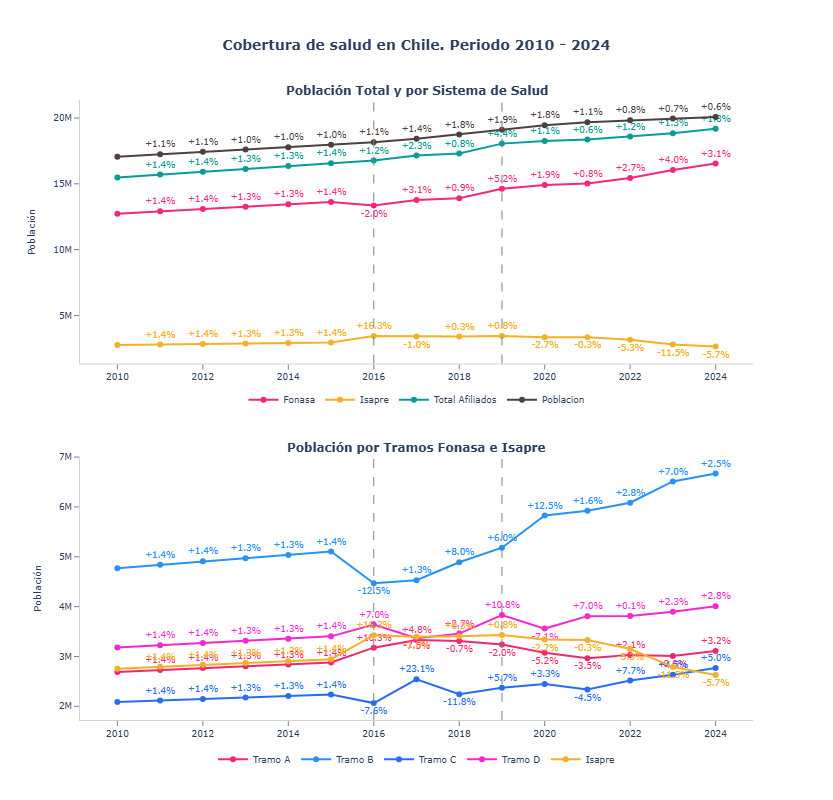

In [40]:
# Agregación y ajuste base

df_graf=df.pivot_table(index='Año', columns='Tramo', values='Beneficiarios', aggfunc='sum').fillna(0).reset_index()
df_graf['Fonasa']=df_graf[['Tramo A', 'Tramo B', 'Tramo C', 'Tramo D']].sum(axis=1)
df_graf['Total Afiliados']=df_graf['Fonasa']+df_graf['Isapre']
df_graf=df_graf.merge(pob.groupby(['Año'])['Poblacion'].sum().rename('Poblacion').reset_index(), on=['Año'], how='left')


df_graf=df_graf.melt(id_vars='Año', value_vars=["Tramo A", "Tramo B", "Tramo C", "Tramo D",'Isapre', 'Fonasa', 'Total Afiliados','Poblacion'],
    var_name='Afiliacion',value_name='Total')

# Cálculo variación porcentual
df_graf["Variacion"] = (df_graf.groupby("Afiliacion")["Total"].pct_change().fillna(0))
df_graf["Variacion_pct"] = (df_graf["Variacion"] * 100).round(2)


# Gráfica

  ## Colores

sistema_colores = {
    "Fonasa": "#F52779",
    "Isapre": "#F5B027",
    "Total Afiliados": "#079C99",
    "Poblacion":"#4D413E"}

tramo_colores = {
    "Tramo A": "#F5276C",
    "Tramo B": "#2791F5",
    "Tramo C": "#276CF5",
    "Tramo D": "#F527D3",
    "Isapre": "#F5B027"}

  ## Configuración

paneles = [
    {"row": 1,
     "titulo": "Población Total y por Sistema de Salud",
     "categorias": ["Fonasa", "Isapre", "Total Afiliados","Poblacion"],
     "colores": sistema_colores,
     "legend": "legend",},

    {"row": 2,
     "titulo": "Población por Tramos Fonasa e Isapre",
     "categorias": ["Tramo A", "Tramo B", "Tramo C", "Tramo D", "Isapre"],
     "colores": tramo_colores,
     "legend": "legend2",}]

  ## Subplots

fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=[p["titulo"] for p in paneles],
    vertical_spacing=0.15)

  ## graficos

for p in paneles:
    df_panel = df_graf[df_graf["Afiliacion"].isin(p["categorias"])]

    for categoria in p["categorias"]:
        datos = df_panel[df_panel["Afiliacion"] == categoria].copy()

        datos["Etiqueta_pct"] = datos["Variacion_pct"].apply(
            lambda x: f"{x:+.1f}%" if x != 0 else "")

        datos["Posicion_texto"] = datos["Variacion_pct"].apply(
            lambda x: "top center" if x >= 0 else "bottom center")

        fig.add_trace(
            go.Scatter(
                x=datos["Año"],
                y=datos["Total"],
                mode="lines+markers+text",
                name=categoria,
                legend=p["legend"],
                line=dict(color=p["colores"][categoria]),
                marker=dict(color=p["colores"][categoria]),
                text=datos["Etiqueta_pct"],
                textposition=datos["Posicion_texto"],
                textfont=dict(
                    size=8.5,
                    color=p["colores"][categoria]),
                customdata=datos["Variacion_pct"]),
            row=p['row'],
            col=1)


 ## Ajustes

  ## Layout
fig.update_annotations(x=0.5, font=dict(size=12, weight='bold'))

for row in [1, 2]:
    fig.update_xaxes(showline=True, linewidth=1, linecolor="lightgray", row=row, col=1, tickfont=dict(size=9), range=[2009.8, None], ticks='outside',tickcolor='gray')
    fig.update_yaxes(title_text="Población", showline=True, linewidth=1,linecolor="lightgray", showgrid=False, gridcolor="lightgray", row=row, col=1, tickfont=dict(size=9), title_font=dict(size=10), ticks='outside',tickcolor='gray')


fig.update_layout(
    title_text='Cobertura de salud en Chile. Periodo 2010 - 2024',
    title_font=dict(size=14, weight='bold'),
    title_x=0.5,
    title_y=0.95,
    height=800,
    width=800,
    plot_bgcolor="white",paper_bgcolor="white",
    legend=dict( x=0.5, y=0.54, xanchor="center",   yanchor="top",  orientation="h", title_text="", font=dict(size=9)),
    legend2=dict( x=0.5, y=-0.04, xanchor="center",  yanchor="top", orientation="h", title_text="", font=dict(size=9)))



#Año=2016 y 2019
fig.add_vline(x=2016, line_width=1, line_dash="dash", line_color="grey")
fig.add_vline(x=2019, line_width=1, line_dash="dash", line_color="grey")

<br>
<br>
...............................................................................................................................................................................................................................................
<br>
<br>

# **Estadísticas descriptivas - Cobertura por variables demográficas**

<br>

## Pirámide poblacional por tramo

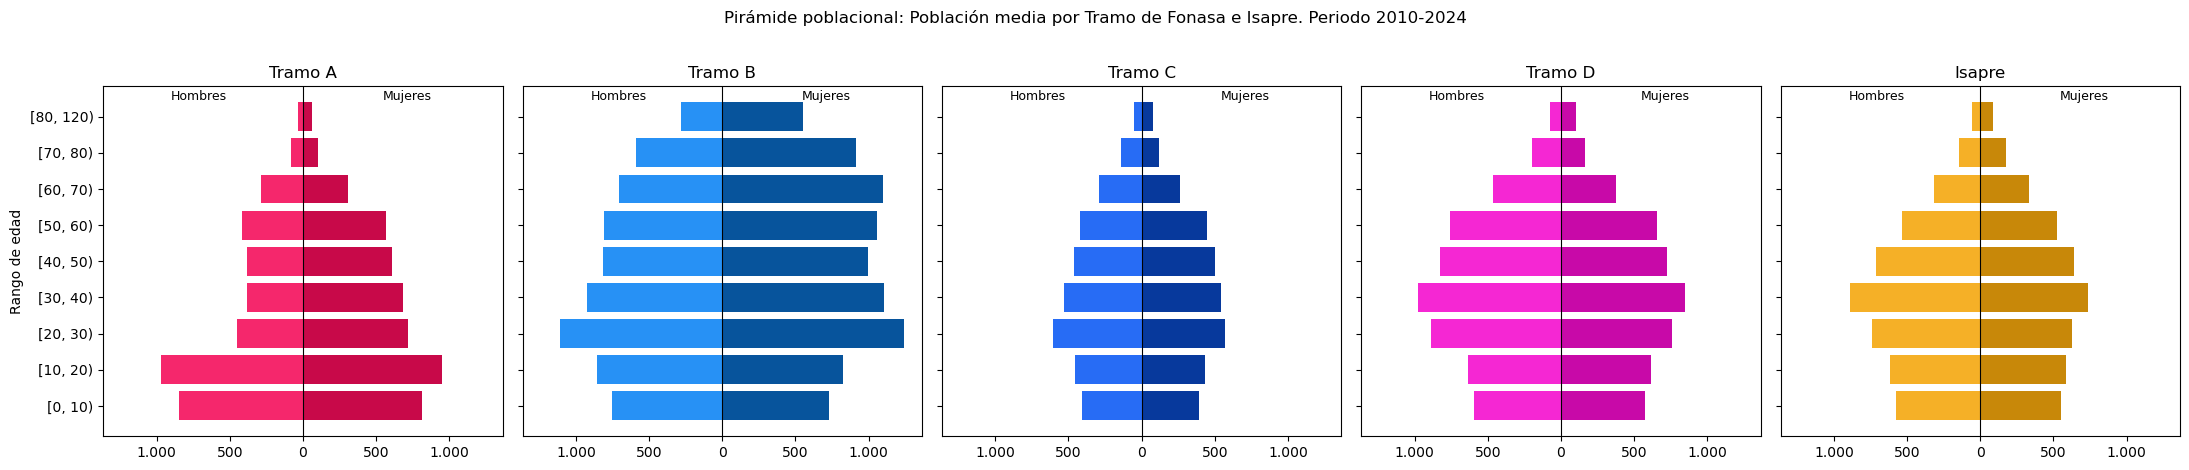

In [42]:
  ## Bases
df_piramide=df.groupby(['Tramo','Sexo','RangoEdad10'])['Beneficiarios'].mean().reset_index()
df_piramide=df_piramide.pivot(index=['RangoEdad10','Tramo'], columns='Sexo', values='Beneficiarios').fillna(0).reset_index()
df_piramide['izq_M']=-df_piramide[1]
df_piramide['der_F']=df_piramide[2]


  ## Gráfico
tramos = ['Tramo A', 'Tramo B', 'Tramo C', 'Tramo D', 'Isapre']

# Define a color dictionary for each tramo
tramo_sexo_colores = {
    'Tramo A': {'Hombres': '#F5276C','Mujeres': '#C80949'},
    'Tramo B': {'Hombres': '#2791F5','Mujeres': '#07549C'},
    'Tramo C': {'Hombres': '#276CF5','Mujeres': '#07399C'},
    'Tramo D': {'Hombres': '#F527D3','Mujeres': '#C809A8'},
    'Isapre': {'Hombres': '#F5B027','Mujeres': '#C88809'}}

max_x = df_piramide[[1, 2]].max().max()

fig, axes = plt.subplots(
    ncols=len(tramos),
    figsize=(22, 5),
    sharex=True,
    sharey=True)


for i, tramo in enumerate(tramos):

    ax = axes[i]

    df_t = df_piramide[
        (df_piramide['Tramo'] == tramo)]

    ax.barh(
        y=df_t['RangoEdad10'],
        width=df_t['izq_M'],
        color=tramo_sexo_colores[tramo]['Hombres'],
        label="Hombres")

    ax.barh(
        y=df_t['RangoEdad10'],
        width=df_t['der_F'],
        color=tramo_sexo_colores[tramo]['Mujeres'],
        label="Mujeres")

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-max_x * 1.1, max_x * 1.1)

    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{abs(int(x)):,}".replace(",", ".")))

  ## Títulos de columnas
    ax.set_title(f"{tramo}")

    if i == 0:
        ax.set_ylabel("Rango de edad")

    # Subtitulo
    ax.text(0.24, 0.97, 'Hombres',transform=ax.transAxes,ha='center', va='center', fontsize=9)

    ax.text(0.76, 0.97, 'Mujeres',transform=ax.transAxes,ha='center', va='center', fontsize=9)


  ## Ajustes

fig.suptitle("Pirámide poblacional: Población media por Tramo de Fonasa e Isapre. Periodo 2010-2024", font=dict(size=14, weight='bold'))

plt.tight_layout(rect=[0, 0.05, 1, 0.96])

plt.show()

### Piramide poblacional general

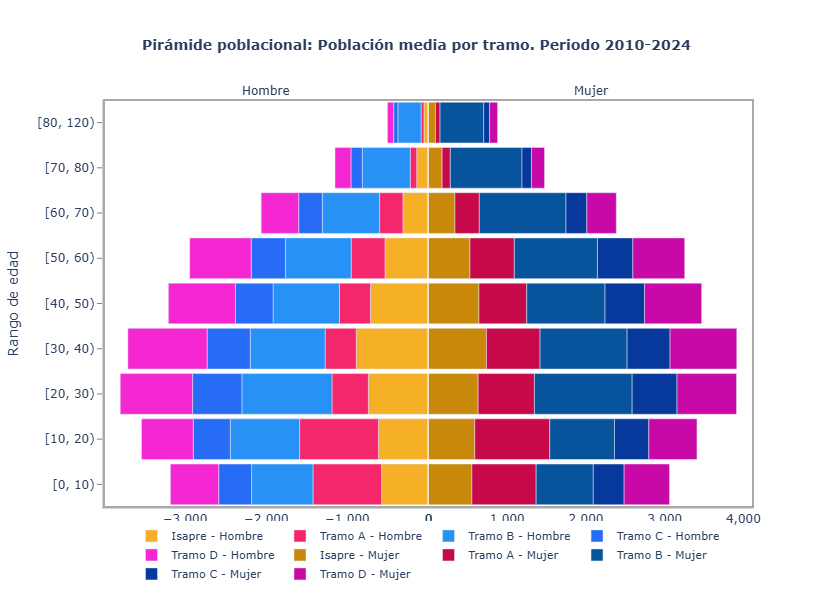

In [46]:
 ## Colores
tramo_sexo_colores = {
    'Tramo A': {'Hombres': '#F5276C','Mujeres': '#C80949'},
    'Tramo B': {'Hombres': '#2791F5','Mujeres': '#07549C'},
    'Tramo C': {'Hombres': '#276CF5','Mujeres': '#07399C'},
    'Tramo D': {'Hombres': '#F527D3','Mujeres': '#C809A8'},
    'Isapre': {'Hombres': '#F5B027','Mujeres': '#C88809'}}

  ## Bases
df_piramide = df.groupby(['Tramo', 'Sexo', 'RangoEdad10'])['Beneficiarios'].mean().reset_index()


  ## Orden rango 'RangoEdad10'
rango_orden = sorted(df_piramide['RangoEdad10'].unique())

  ## subplot hombre y mujers
fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0,
                    subplot_titles=('Hombre', 'Mujer'))

fig.update_annotations(font_size=12)

for i, sexo_val in enumerate([1, 2]):
    sexo_data = df_piramide[df_piramide['Sexo'] == sexo_val].copy()

  ## Ordenar rango del grafico
    sexo_data['RangoEdad10'] = pd.Categorical(sexo_data['RangoEdad10'], categories=rango_orden, ordered=True)
    sexo_data = sexo_data.sort_values('RangoEdad10')

  ## Barras
    for tramo in sorted(sexo_data['Tramo'].unique()):
        tramo_data = sexo_data[sexo_data['Tramo'] == tramo]

        ## Hombres (-1)
        x_values = tramo_data['Beneficiarios'] if sexo_val == 2 else -tramo_data['Beneficiarios']

        # Color por sexo
        sexo_color = tramo_sexo_colores[tramo]['Mujeres'] if sexo_val == 2 else tramo_sexo_colores[tramo]['Hombres']

        fig.add_trace(
            go.Bar(
                y=tramo_data['RangoEdad10'],
                x=x_values,
                name=f"{tramo} - {'Mujer' if sexo_val == 2 else 'Hombre'}",
                orientation='h',
                marker_color=sexo_color,
                hovertemplate=f'<b>Rango de Edad</b>: %{{y}}<br><b>Tramo</b>: {tramo}<br><b>Beneficiarios</b>: %{{x:,.0f}}<extra></extra>',
                showlegend=True),
            row=1, col=i + 1)

  ## Layout
fig.update_layout(
    title_text='Pirámide poblacional: Población media por tramo. Periodo 2010-2024',
    title_font=dict(size=14, weight='bold'),
    title_x=0.5,
    barmode='relative',
    bargap=0.1,
    height=600,
    width=1000,
    yaxis_title='Rango de edad',
    plot_bgcolor='white',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=-0.2,
        xanchor='center',
        x=0.5,
        font=dict(size=11)))

# Estética ejes
fig.update_xaxes( tickformat=',.0f', row=1, col=1, linewidth=2,linecolor="lightgray", showgrid=False, gridcolor="gray")
fig.update_xaxes( tickformat=',.0f', row=1, col=2, linewidth=2,linecolor="lightgray", showgrid=False, gridcolor="gray")

fig.update_yaxes(categoryorder='array', row=1,col=1, categoryarray=rango_orden, linewidth=2,linecolor="lightgray", showgrid=False, gridcolor="gray",
                 ticks='outside',tickcolor='gray')
fig.update_yaxes(categoryorder='array', row=1, col=2, categoryarray=rango_orden)

fig.add_shape(type='rect',xref='paper',yref='paper',x0=0,y0=0,x1=1,y1=1,
    line=dict(color='darkgray',width=2),
    fillcolor='rgba(0,0,0,0)',
    layer='above')

fig.show()

<br>

### Análisis por estratos

In [49]:
# Agrupar datos por Año, Sexo y RangoEdad10
  ## Bases
pob_estrato=pob.groupby(['Año','Sexo','RangoEdad10'])['Poblacion'].sum().reset_index()
df_estratos=df.groupby(['Año','Tramo','Sexo','RangoEdad10'])['Beneficiarios'].sum().reset_index().merge(pob_estrato,on=['Año','Sexo','RangoEdad10'],how='left')

  ## Métricas
metricas_estrato = df_estratos.groupby(['Sexo', 'RangoEdad10'])['Beneficiarios'].describe()
metricas_estrato['RIQ'] = metricas_estrato['75%'] - metricas_estrato['25%']

metricas_estrato = metricas_estrato[['mean', 'std', 'max', 'min', 'RIQ']].rename(columns={
    'mean': 'Media',
    'std': 'Desvest',
    'max': 'Max',
    'min': 'Min'})

metricas_estrato = metricas_estrato.reset_index()

  ## Ajustes estética
metricas_estrato['Sexo'] = metricas_estrato['Sexo'].map({1: 'Hombre', 2: 'Mujer', 99: 'Sin Sexo'})
metricas_estrato['Indic'] = metricas_estrato['Sexo'] + ' - ' + metricas_estrato['RangoEdad10'].astype(str)

metricas_estrato = metricas_estrato[['Indic', 'Media', 'Desvest', 'Max', 'Min', 'RIQ']]

metricas_estrato[['Max', 'Min']] = \
metricas_estrato[['Max', 'Min']].astype(int)


metricas_estrato[['Media','Desvest','RIQ']] = \
metricas_estrato[['Media','Desvest','RIQ']].round(2)
metricas_estrato=metricas_estrato.style.format({'Media': '{:,.2f}', 'Desvest': '{:,.2f}', 'Max': '{:,.0f}', 'Min': '{:,.0f}', 'RIQ': '{:,.2f}'})

display(metricas_estrato)

,Indic,Media,Desvest,Max,Min,RIQ
0,"Hombre - [0, 10)","220,070.59","74,408.92","405,928","121,221","58,222.50"
1,"Hombre - [10, 20)","244,667.83","86,825.43","450,565","125,321","77,484.00"
2,"Hombre - [20, 30)","262,825.65","93,812.26","450,974","96,994","126,772.50"
3,"Hombre - [30, 40)","256,310.23","109,764.91","499,522","76,881","157,506.00"
4,"Hombre - [40, 50)","221,767.84","79,248.01","370,369","90,124","129,804.00"
5,"Hombre - [50, 60)","203,611.53","67,223.16","333,157","114,812","115,178.50"
6,"Hombre - [60, 70)","142,679.03","66,560.19","372,913","68,801","75,185.00"
7,"Hombre - [70, 80)","79,738.07","76,128.00","301,871","5,230","29,400.00"
8,"Hombre - [80, 120)","35,015.69","38,891.50","159,434","3,543","12,507.50"
9,"Mujer - [0, 10)","211,847.04","71,654.88","391,160","117,291","54,973.50"


<br>
<br>
...............................................................................................................................................................................................................................................
<br>
<br>

# **Estadísticas descriptivas - Cobertura por región y comuna**

<br>

### Cobertura de comunas por región
Se agrega la información por año, región y comuna y se obtiene las estadísticas.

In [53]:
# Ajuste comunas
diccionario_region={
    "Libertador General Bernardo O'Higgins": "O'Higgins",
    'Aysén del General Carlos Ibáñez del Campo': 'Aysén',
    'Magallanes y de la Antártica Chilena': 'Magallanes',
    'Metropolitana de Santiago': 'Metropolitana'}


comuna['Nombre Region'] = comuna['Nombre Region'].map(diccionario_region).fillna(comuna['Nombre Region'])

In [55]:
# Incorporación de nombres de comunas y regiones

  ## Nombres

nombres=(comuna[['Region','Nombre Region','Comuna','Nombre Comuna']].drop_duplicates())


def regiones_antiguas(region):
  match region:
    case 14: return 10
    case 15: return 1
    case 16: return 8
    case _: return region

nombres=nombres.assign(Region13=nombres.Region.apply(regiones_antiguas))

total = nombres.groupby('Region')['Comuna'].nunique().reset_index(name='Total comunas')

  ## Incorporación de comuna y region
df= df.merge(comuna[['Comuna','Region','Nombre Region']], on=['Comuna','Region'], how='left')

In [59]:
# Estadísticas

  ## Agrupación todas las comunas
df_comunas=df.groupby(['Año','Comuna'])['Beneficiarios'].sum().reset_index()

  ## Métricas todas las comunas

metricas_comunas = df_comunas['Beneficiarios'].describe().reset_index()
metricas_comunas['Total comunas']=df_comunas['Comuna'].nunique()

metricas_comunas=pd.pivot_table(metricas_comunas, index='Total comunas',columns='index', values='Beneficiarios')

metricas_comunas['RIQ'] = metricas_comunas['75%'] - metricas_comunas['25%']
metricas_comunas = metricas_comunas.rename(columns={
    'mean': 'Media',
    'std': 'Desvest',
    'max': 'Max',
    'min': 'Min'}).reset_index()

metricas_comunas['Nombre Region']='Todas las comunas'


metricas_comunas=metricas_comunas[['Nombre Region','Total comunas', 'Media', 'Desvest', 'Max', 'Min', 'RIQ']]

  ## Agrupación base por Región

df_region=df.groupby(['Año','Region','Comuna'])['Beneficiarios'].sum().reset_index()


  ## Métricas por Región

metricas_region = df_region.groupby("Region")['Beneficiarios'].describe().reset_index()
metricas_region['RIQ'] = metricas_region['75%'] - metricas_region['25%']
metricas_region = metricas_region.rename(columns={
    'mean': 'Media',
    'std': 'Desvest',
    'max': 'Max',
    'min': 'Min'})

metricas_region=metricas_region[['Region','Media', 'Desvest', 'Max', 'Min', 'RIQ']]


  # Nombre de Región y Totales
metricas_region=metricas_region.merge(nombres[['Region','Nombre Region','Region13']].drop_duplicates(), on='Region', how='left')
metricas_region=metricas_region.merge(total, on='Region', how='left')


# Tabla final
metricas_region=pd.concat([metricas_region,metricas_comunas], ignore_index=True)

metricas_region[['Max', 'Min']] = \
metricas_region[['Max', 'Min']].astype(int)


metricas_region[['Media', 'Desvest','RIQ']] = \
metricas_region[['Media', 'Desvest','RIQ']].round(2)

metricas_region = metricas_region.sort_values('Region13')[['Nombre Region','Total comunas', 'Media', 'Desvest', 'Max', 'Min', 'RIQ']]


print("Estadística descriptiva por región")
Tabla_5=metricas_region.style.format({'Media': '{:,.2f}', 'Desvest': '{:,.2f}', 'Max': '{:,.0f}', 'Min': '{:,.0f}', 'RIQ': '{:,.2f}'})
Tabla_5

Estadística descriptiva por región


,Nombre Region,Total comunas,Media,Desvest,Max,Min,RIQ
0,Tarapacá,7,"45,791.56","72,140.99","230,526",5,"80,490.00"
14,Arica y Parinacota,4,"54,759.47","95,648.48","257,460",4,"48,103.50"
1,Antofagasta,9,"65,458.81","121,821.88","434,265",59,"15,492.50"
2,Atacama,9,"32,373.01","46,233.95","174,785","4,447","10,343.00"
3,Coquimbo,15,"48,753.10","74,811.79","271,469","1,014","25,012.00"
4,Valparaíso,38,"45,497.76","69,104.11","346,302",262,"31,600.75"
5,O'Higgins,33,"27,332.25","44,307.47","277,667","2,634","16,815.00"
6,Maule,30,"34,679.09","49,081.22","265,133","2,626","30,632.25"
7,Biobío,33,"46,327.63","56,719.99","252,373","2,922","38,044.50"
15,Ñuble,21,"22,100.41","38,424.84","199,310","2,003","12,131.50"


<br>

### Comparación de totales por región y tasas de cobertura.

In [61]:
# Obtener valores media de las regiones

# Bases
pob_region=pob.groupby(['Año','Region'])['Poblacion'].sum().reset_index()

  ## Suma del total de region por año
df_tramo_region=df.groupby(['Año','Nombre Region','Region','Tramo'])['Beneficiarios'].sum().reset_index()
df_tramo_region=df_tramo_region.pivot(index=['Año','Nombre Region','Region'], columns='Tramo', values='Beneficiarios').reset_index().merge(pob_region, on=['Año','Region'], how='left')

  ## Obtener Cobertura N/I
df_tramo_region['Cobertura N/I']=df_tramo_region['Poblacion']-(df_tramo_region['Tramo A']+df_tramo_region['Tramo B']+df_tramo_region['Tramo C']+df_tramo_region['Tramo D']+df_tramo_region['Isapre'])
df_tramo_region=df_tramo_region.melt(id_vars=['Año','Nombre Region','Region','Poblacion'], value_vars=["Tramo A", "Tramo B", "Tramo C", "Tramo D",'Isapre', 'Cobertura N/I'],
    var_name='Tramo',value_name='Beneficiarios')

  ## Calcular media
df_tramo_region_mean=df_tramo_region.groupby(['Nombre Region','Region','Tramo'])['Beneficiarios'].mean().reset_index().rename(columns={'Beneficiarios':'Benef_Media'})
df_tramo_region_mean['Benef_Media']=df_tramo_region_mean['Benef_Media'].round(2)


In [63]:
# Tasa de cobertura

  ## Suma de beneficiarios
df_tramo_region=df_tramo_region.groupby(['Nombre Region','Region','Tramo'])[['Beneficiarios']].sum().reset_index().merge(pob.groupby(['Region'])['Poblacion'].sum().reset_index(), on=['Region'], how='left')

  ## Tasa de cobertura
df_tramo_region['Tasa Cobertura']=((df_tramo_region['Beneficiarios']/df_tramo_region['Poblacion'])*100).round(2)

  ## Unir bases
df_tramo_region=df_tramo_region.merge(df_tramo_region_mean, on=['Nombre Region','Region','Tramo'], how='left')
df_tramo_region=df_tramo_region.drop(columns=['Beneficiarios']).rename(columns={'Benef_Media':'Beneficiarios'})

  ## Incorporar Region13
df_tramo_region=df_tramo_region.assign(Region13=df_tramo_region.Region.apply(regiones_antiguas))

In [65]:
# Tabla
Tabla_6=df_tramo_region.pivot(index=['Region13','Nombre Region'], columns='Tramo', values='Tasa Cobertura').fillna(0).reset_index().sort_values(by=['Region13'])

Tabla_6=Tabla_6.rename(columns={col:f"{col} (%)" for col in columnas})

Tabla_6=Tabla_6[['Region13','Nombre Region','Tramo A (%)','Tramo B (%)','Tramo C (%)','Tramo D (%)','Isapre (%)','Cobertura N/I']]
Tabla_6

Tramo,Region13,Nombre Region,Tramo A (%),Tramo B (%),Tramo C (%),Tramo D (%),Isapre (%),Cobertura N/I
0,1,Arica y Parinacota,20.17,29.54,11.74,18.14,12.01,8.40
1,1,Tarapacá,19.80,25.76,12.78,18.86,14.42,8.38
2,2,Antofagasta,13.27,23.70,12.27,21.19,21.74,7.83
3,3,Atacama,16.76,27.47,13.03,23.21,15.09,4.45
4,4,Coquimbo,16.16,30.15,13.03,20.72,12.00,7.95
5,5,Valparaíso,15.11,30.53,12.97,19.15,13.74,8.50
6,6,O'Higgins,14.94,32.82,13.19,19.46,14.00,5.58
7,7,Maule,18.44,33.67,13.37,18.54,11.12,4.87
8,8,Biobío,17.73,30.12,12.91,19.70,13.17,6.37
9,8,Ñuble,18.98,33.57,12.56,17.23,10.40,7.27


<br>

### Visualización población por región

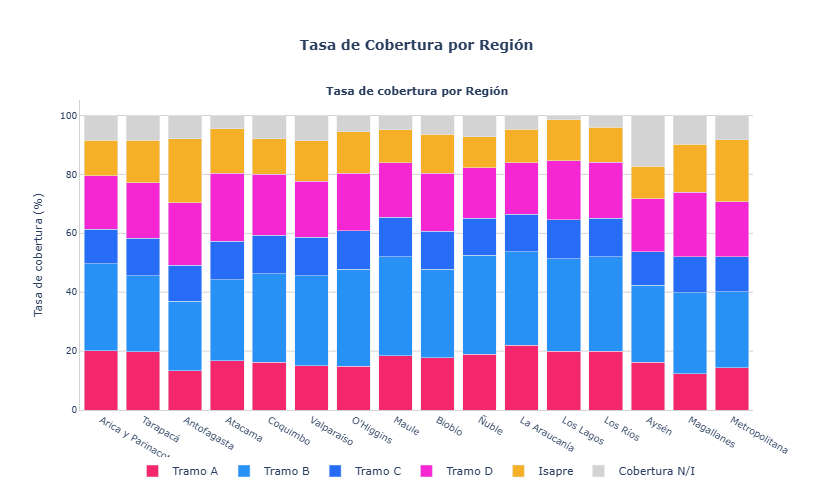

In [69]:
 ## Base
df_tramo_region=df_tramo_region.sort_values(by=['Region13', 'Tramo'])

  ## Colores
tramo_colores = {
    "Tramo A": "#F5276C",
    "Tramo B": "#2791F5",
    "Tramo C": "#276CF5",
    "Tramo D": "#F527D3",
    "Isapre": "#F5B027",
    "Cobertura N/I":"lightgrey"}

# Gráfico

  ## Preparación datos
Tramos_graf = ['Tramo A', 'Tramo B', 'Tramo C', 'Tramo D', 'Isapre', 'Cobertura N/I']

  ## Subplot
fig = make_subplots(
    rows=1,
    cols=1,
    subplot_titles=[
        '<b>Tasa de cobertura por Región<b>'],
    shared_xaxes=True,
    shared_yaxes=False)


## Gráfico 2: Tasa Cobertura
fig_temp_tasa = px.bar(
    df_tramo_region,
    x='Nombre Region',
    y='Tasa Cobertura',
    color='Tramo',
    category_orders={'Tramo': Tramos_graf},
    color_discrete_map=tramo_colores)

for trace in fig_temp_tasa.data:
    trace.showlegend = True
    fig.add_trace(trace, row=1, col=1)


## Layout
fig.update_layout(
    title_text='Tasa de Cobertura por Región',
    title_font=dict(size=14, weight='bold'),
    title_x=0.5,
    height=500,
    width=800,
    barmode='stack',
    plot_bgcolor='white',
    paper_bgcolor='white',
    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.15,
        xanchor="center",
        x=0.5,
        font=dict(size=11)))

fig.update_annotations(font_size=11)


fig.update_xaxes(title_text='', tickfont=dict(size=9.5), title_font=dict(size=10),  row=1, col=1, linewidth=1,linecolor="lightgray", showgrid=False, gridcolor="lightgray")

fig.update_yaxes( title_text='Tasa de cobertura (%)', tickfont=dict(size=9),title_font=dict(size=11), row=1, col=1, linewidth=1,linecolor="lightgray", showgrid=True, gridcolor="lightgray")

fig.show()

<br>

### Cobertura por comunas y Tasas de Cobertura por tramo


In [71]:
#Bases
pob_comuna=pob.groupby(['Año','Comuna'])['Poblacion'].sum().reset_index()
df_tramo_comuna=df.groupby(['Año','Comuna','Tramo'])['Beneficiarios'].sum().reset_index()

  ## Métricas registros
metricas_tramo = df_tramo_comuna.groupby('Tramo')['Beneficiarios'].describe()
metricas_tramo['RIQ'] = metricas_tramo['75%'] - metricas_tramo['25%']
metricas_tramo = metricas_tramo.reset_index()

metricas_tramo[['max', 'min']] = \
metricas_tramo[['max', 'min']].astype(int)


metricas_tramo[['mean', 'std','RIQ']] = \
metricas_tramo[['mean', 'std','RIQ']].round(2)

metricas_tramo=metricas_tramo[['Tramo','mean', 'std', 'min','max','RIQ']]

  ## Métricas tasa cobetura

df_tramo_comuna = df_tramo_comuna.merge(pob_comuna, on=['Año','Comuna'], how='left')
df_tramo_comuna['Tasa Cobertura']=((df_tramo_comuna['Beneficiarios']/df_tramo_comuna['Poblacion'])*100).round(2)

metricas_tramo_tasa =df_tramo_comuna.groupby('Tramo')['Tasa Cobertura'].describe()
metricas_tramo_tasa['RIQ'] = metricas_tramo_tasa['75%'] - metricas_tramo_tasa['25%']
metricas_tramo_tasa=metricas_tramo_tasa.reset_index()


metricas_tramo_tasa[['max', 'min']] = \
metricas_tramo_tasa[['max', 'min']].astype(int)


metricas_tramo_tasa[['mean', 'std','RIQ']] = \
metricas_tramo_tasa[['mean', 'std','RIQ']].round(2)

metricas_tramo_tasa=metricas_tramo_tasa[['Tramo','mean', 'std', 'min','max','RIQ']]


In [73]:
# Reordenar para unir

  ## Data Afiliacion
metricas_tramo['Reg']="Registro Afiliación"
metricas_tramo=metricas_tramo.melt(id_vars=['Tramo','Reg'],value_vars=['mean','std','min','max','RIQ'],
                    var_name="estad",value_name='Valor')
metricas_tramo['estad']=metricas_tramo['estad'].map({'mean':'Media','std':'Desvest','min':'Mín','max':'Máx','RIQ':'RIQ'})

  ## Data Tasa cobertura
metricas_tramo_tasa['Reg']="Registro Tasa Cobertura"
metricas_tramo_tasa=metricas_tramo_tasa.melt(id_vars=['Tramo','Reg'],value_vars=['mean','std','min','max','RIQ'],
                    var_name="estad",value_name='Valor')
metricas_tramo_tasa['estad']=metricas_tramo_tasa['estad'].map({'mean':'Media','std':'Desvest','min':'Mín','max':'Máx','RIQ':'RIQ'})

  ## base final
Tabla_7=pd.concat([metricas_tramo,metricas_tramo_tasa], ignore_index=True)
Tabla_7=Tabla_7.pivot(index=['Tramo'], columns=['Reg','estad'], values='Valor').reset_index()
Tabla_7.columns.name = None
Tabla_7

Reg      Tramo Registro Afiliación                                 \
estad                        Media   Desvest Mín     Máx      RIQ   
0       Isapre             8861.31   20066.3   0  235907  6362.25   
1      Tramo A             8660.88  12342.59   0   83361   8022.0   
2      Tramo B            15361.39   22686.9   0  174218  13770.5   
3      Tramo C             6724.24  10503.77   0   82522  5768.75   
4      Tramo D            10237.54   16349.9   0  126490   8460.5   

Reg   Registro Tasa Cobertura                         
estad                   Media Desvest Mín Máx    RIQ  
0                       11.11     8.9   0  82  12.96  
1                       17.76    7.76   0  53   7.27  
2                       29.27    9.76   0  68   9.07  
3                        11.7    3.51   0  24   3.46  
4                       17.56     5.3   0  39   5.73

-----------------------------------------------------------------------------------------------------------------------------------------------------------------
<br>
<br>

# Estadísticas descriptivas - demográfico y territorial

## Boxplot estratos por comuna

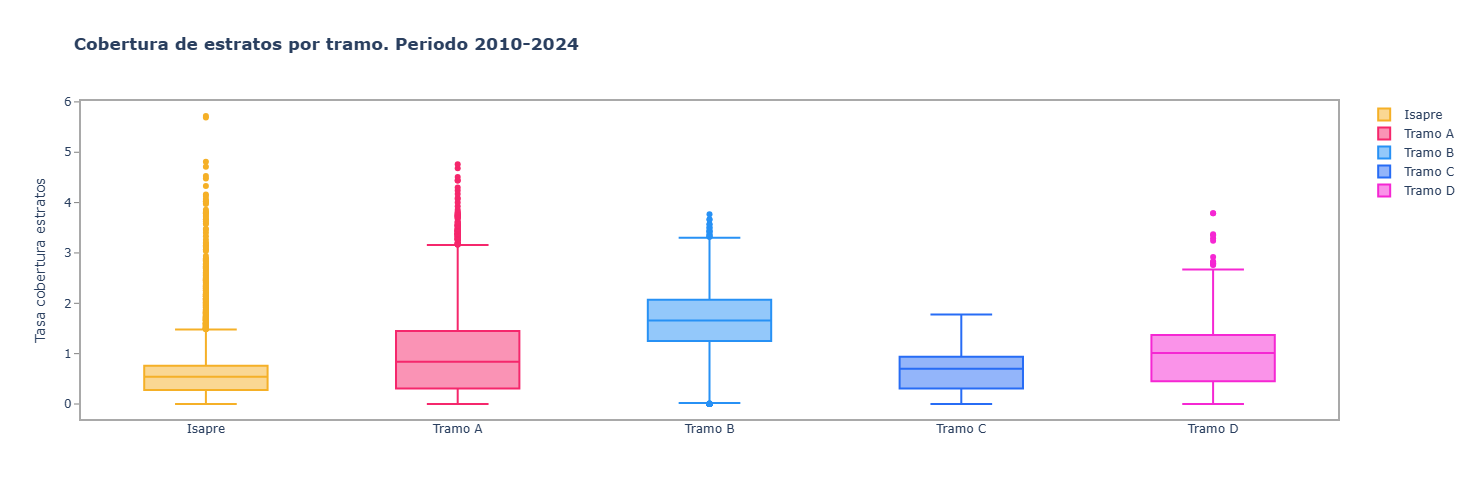

In [77]:
  ## Bases
df_estratos=df.groupby(['Comuna','Tramo','Sexo','RangoEdad10'])['Beneficiarios'].sum().reset_index()
df_estratos=df_estratos.merge(pob.groupby(['Comuna'])['Poblacion'].sum().reset_index(), on=['Comuna'], how='left')
df_estratos['Tasa cobertura']=((df_estratos['Beneficiarios']/df_estratos['Poblacion'])*100).round(2)

df_estratos=(df_estratos.merge(comuna[['Comuna', 'Nombre Comuna']].drop_duplicates(), on='Comuna', how='left')).groupby(['Tramo','Sexo','RangoEdad10','Nombre Comuna'])['Tasa cobertura'].mean().reset_index()

  ## Grafica
fig = px.box(
    df_estratos,
    x='Tramo',
    y='Tasa cobertura',
    title='<b>Cobertura de estratos por tramo. Periodo 2010-2024<b>',
    labels={
        'Tramo': "",
        'Tasa cobertura': 'Tasa cobertura estratos'},
    color='Tramo',
    color_discrete_map=tramo_colores,
    height=500,
    width=800,
    hover_data=['Nombre Comuna'])

fig.update_layout(
    plot_bgcolor='white',
    paper_bgcolor='white')

fig.add_shape(type='rect',xref='paper',yref='paper',x0=0,y0=0,x1=1,y1=1,
    line=dict(color='darkgray',width=2),
    fillcolor='rgba(0,0,0,0)',
    layer='above')


fig.update_yaxes(ticks='outside',tickcolor='gray')

fig.show()

-----------------------------------------------------------------------------------------------------------------------------------------------------------------
<br>
<br>

# **Tendencia por Comunas**

In [4]:
cobs = (df.merge(pob.drop(columns='Region'), on=['Año','Comuna','Sexo','RangoEdad10'], how='left').
        merge(comuna[['Comuna','Nombre Comuna','Nombre Region']], on='Comuna', how='left').
        replace({'Tramo':{'Tramo ':'Fonasa'}},regex=True).
        assign(Cobertura=lambda x: x.Beneficiarios/x.Poblacion))[lambda x: ((x.Año>2015))] #(x.Region>=13)&

regionSort = {15:1, 1:2, 2:3, 3:4, 4:5, 5:6, 13:7, 6:8, 7:9, 16:10, 8:11, 9:12, 14:13, 10:14, 11:15, 12:16}


cobs['RegionSorted'] = cobs.Region.map(regionSort)

cobs['ComunaSorted'] = cobs.RegionSorted*1000000 + cobs.Comuna
cobs = cobs.sort_values(by='ComunaSorted')


cobs

,Año,Region,Comuna,Tramo,Sexo,RangoEdad10,Beneficiarios,Poblacion,Nombre Comuna,Nombre Region,Cobertura,RegionSorted,ComunaSorted
402625,2022,15,15101,FonasaC,1,"[10, 20)",1949,18694,Arica,Arica y Parinacota,0.104258,1,1015101
402624,2022,15,15101,FonasaC,1,"[0, 10)",1581,17017,Arica,Arica y Parinacota,0.092907,1,1015101
402591,2022,15,15101,FonasaA,1,"[30, 40)",2273,20417,Arica,Arica y Parinacota,0.111329,1,1015101
402590,2022,15,15101,FonasaA,1,"[20, 30)",2823,21268,Arica,Arica y Parinacota,0.132735,1,1015101
402571,2022,15,15101,Isapre,1,"[10, 20)",1517,18694,Arica,Arica y Parinacota,0.081149,1,1015101
...,...,...,...,...,...,...,...,...,...,...,...,...,...
459002,2024,12,12402,Isapre,1,"[20, 30)",1,193,Torres del Paine,Magallanes y de la Antártica Chilena,0.005181,16,16012402
334449,2020,12,12402,Isapre,2,"[0, 10)",1,26,Torres del Paine,Magallanes y de la Antártica Chilena,0.038462,16,16012402
334448,2020,12,12402,Isapre,1,"[80, 120)",0,3,Torres del Paine,Magallanes y de la Antártica Chilena,0.0,16,16012402
334447,2020,12,12402,Isapre,1,"[70, 80)",0,24,Torres del Paine,Magallanes y de la Antártica Chilena,0.0,16,16012402


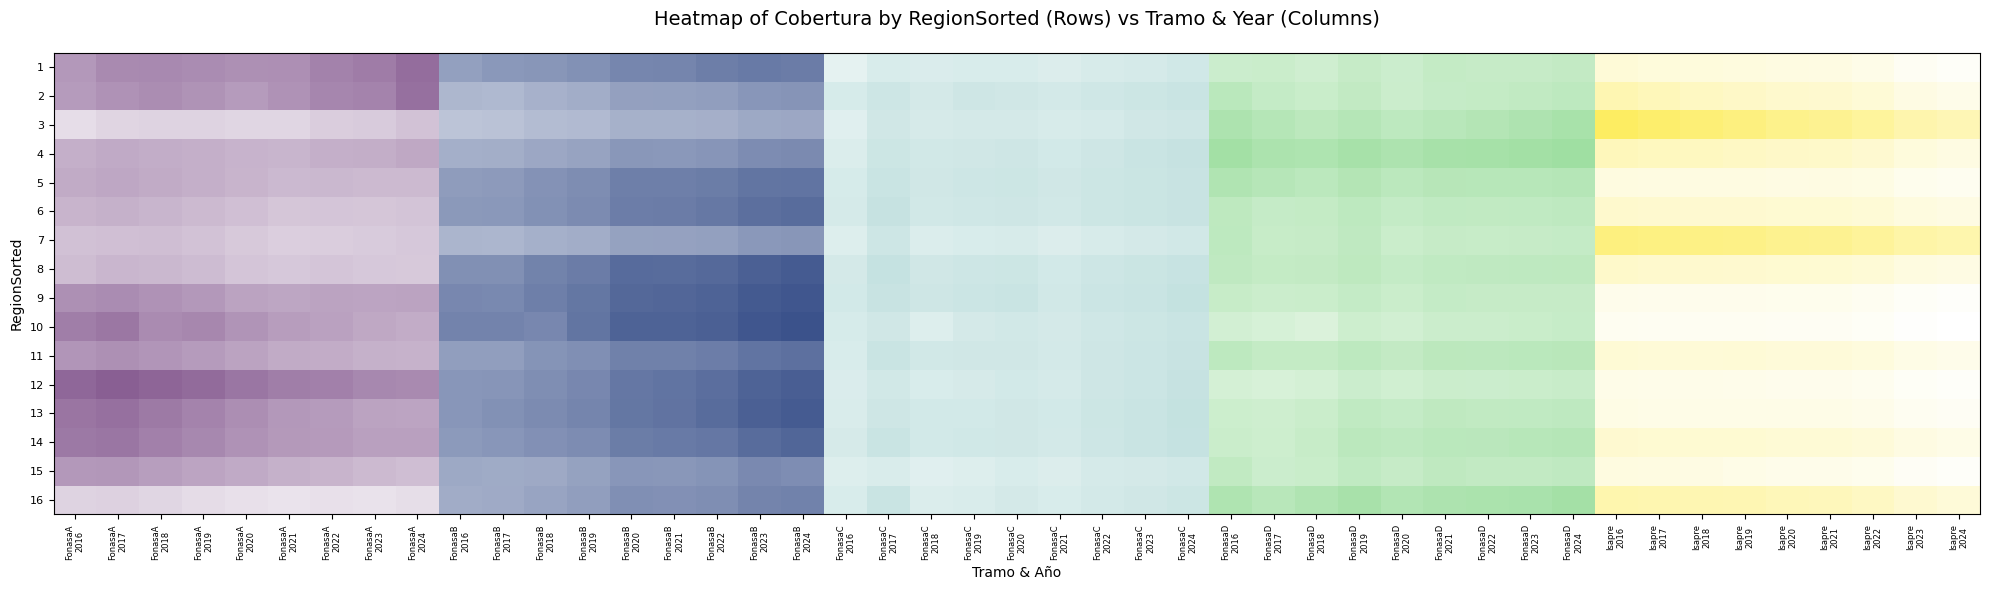

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

# ======================================================================
# PARAMETER: Set your row grouping variable here.
# Options: 'Comuna', 'RangoEdad10', or 'Sexo'
# ======================================================================
row_variable = 'Comuna'

def plot_heatmap(df, row_variable):

  # Ensure clean, sorted structures
  tramo_order = ['FonasaA', 'FonasaB', 'FonasaC', 'FonasaD', 'Isapre']

  # Group dynamically based on the selected row variable
  df_heat = df.groupby([row_variable, 'Tramo', 'Año'])[['Beneficiarios','Poblacion']].sum().reset_index()
  df_heat['Cobertura'] = (df_heat['Beneficiarios']/df_heat['Poblacion'])

  # Map Sexo to human-readable names if selected
  if row_variable == 'Sexo':
      df_heat['Sexo'] = df_heat['Sexo'].map({1: 'Mujer', 2: 'Hombre'}).fillna(df_heat['Sexo'])

  # Get sorted unique categories for rows and columns
  row_categories = sorted(df_heat[row_variable].unique())
  years_list = sorted(df_heat['Año'].unique())

  # Construct the index (rows) and columns of the heatmap
  row_tuples = row_categories
  col_tuples = [(tr, yr) for tr in tramo_order for yr in years_list]

  # Map elements to matrix coordinates
  row_map = {val: i for i, val in enumerate(row_tuples)}
  col_map = {val: j for j, val in enumerate(col_tuples)}

  # Map Tramos to viridis colors
  viridis_cmap = plt.get_cmap('viridis')
  tramo_colors = {tramo: viridis_cmap(i / (len(tramo_order) - 1)) for i, tramo in enumerate(tramo_order)}

  # Normalize Cobertura to [0, 1] range safely for alpha transparency
  min_cob = df_heat['Cobertura'].min()
  max_cob = df_heat['Cobertura'].max()
  span = (max_cob - min_cob) if (max_cob - min_cob) > 0 else 1.0
  df_heat['Alpha'] = (df_heat['Cobertura'] - min_cob) / span

  # Adjust height of figure dynamically based on the number of categories
  fig_height = max(5, int(len(row_tuples) * 0.25)) if row_variable == 'Comuna' else 6
  fig, ax = plt.subplots(figsize=(20, fig_height), dpi=100)

  # Render each cell as a colored rectangle with alpha matching scaled Cobertura
  for _, row in df_heat.iterrows():
      r_key = row[row_variable]
      c_key = (row['Tramo'], row['Año'])

      if r_key in row_map and c_key in col_map:
          y = row_map[r_key]
          x = col_map[c_key]
          base_color = tramo_colors[row['Tramo']]
          alpha_val = float(row['Alpha'])
          rgba_color = (base_color[0], base_color[1], base_color[2], alpha_val)

          rect = Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=rgba_color, edgecolor='none')
          ax.add_patch(rect)

  # Grid boundaries and limits
  ax.set_xlim(-0.5, len(col_tuples) - 0.5)
  ax.set_ylim(-0.5, len(row_tuples) - 0.5)

  # Setup row labels
  y_ticks = np.arange(len(row_tuples))
  y_labels = [str(val) for val in row_tuples]
  ax.set_yticks(y_ticks)
  ax.set_yticklabels(y_labels, fontsize=8 if row_variable != 'Comuna' else 6)

  # Setup column labels
  x_ticks = np.arange(len(col_tuples))
  x_labels = [f"{tr}\n{yr}" for tr, yr in col_tuples]
  ax.set_xticks(x_ticks)
  ax.set_xticklabels(x_labels, fontsize=6, rotation=90)

  # Style modifications
  ax.invert_yaxis()  # Put top-sorted item at the top
  ax.set_title(f"Heatmap of Cobertura by {row_variable} (Rows) vs Tramo & Year (Columns)", fontsize=14, pad=20)
  ax.set_xlabel("Tramo & Año", fontsize=10)
  ax.set_ylabel(row_variable, fontsize=10)

  plt.tight_layout()
  plt.show()


plot_heatmap(cobs, "RegionSorted")

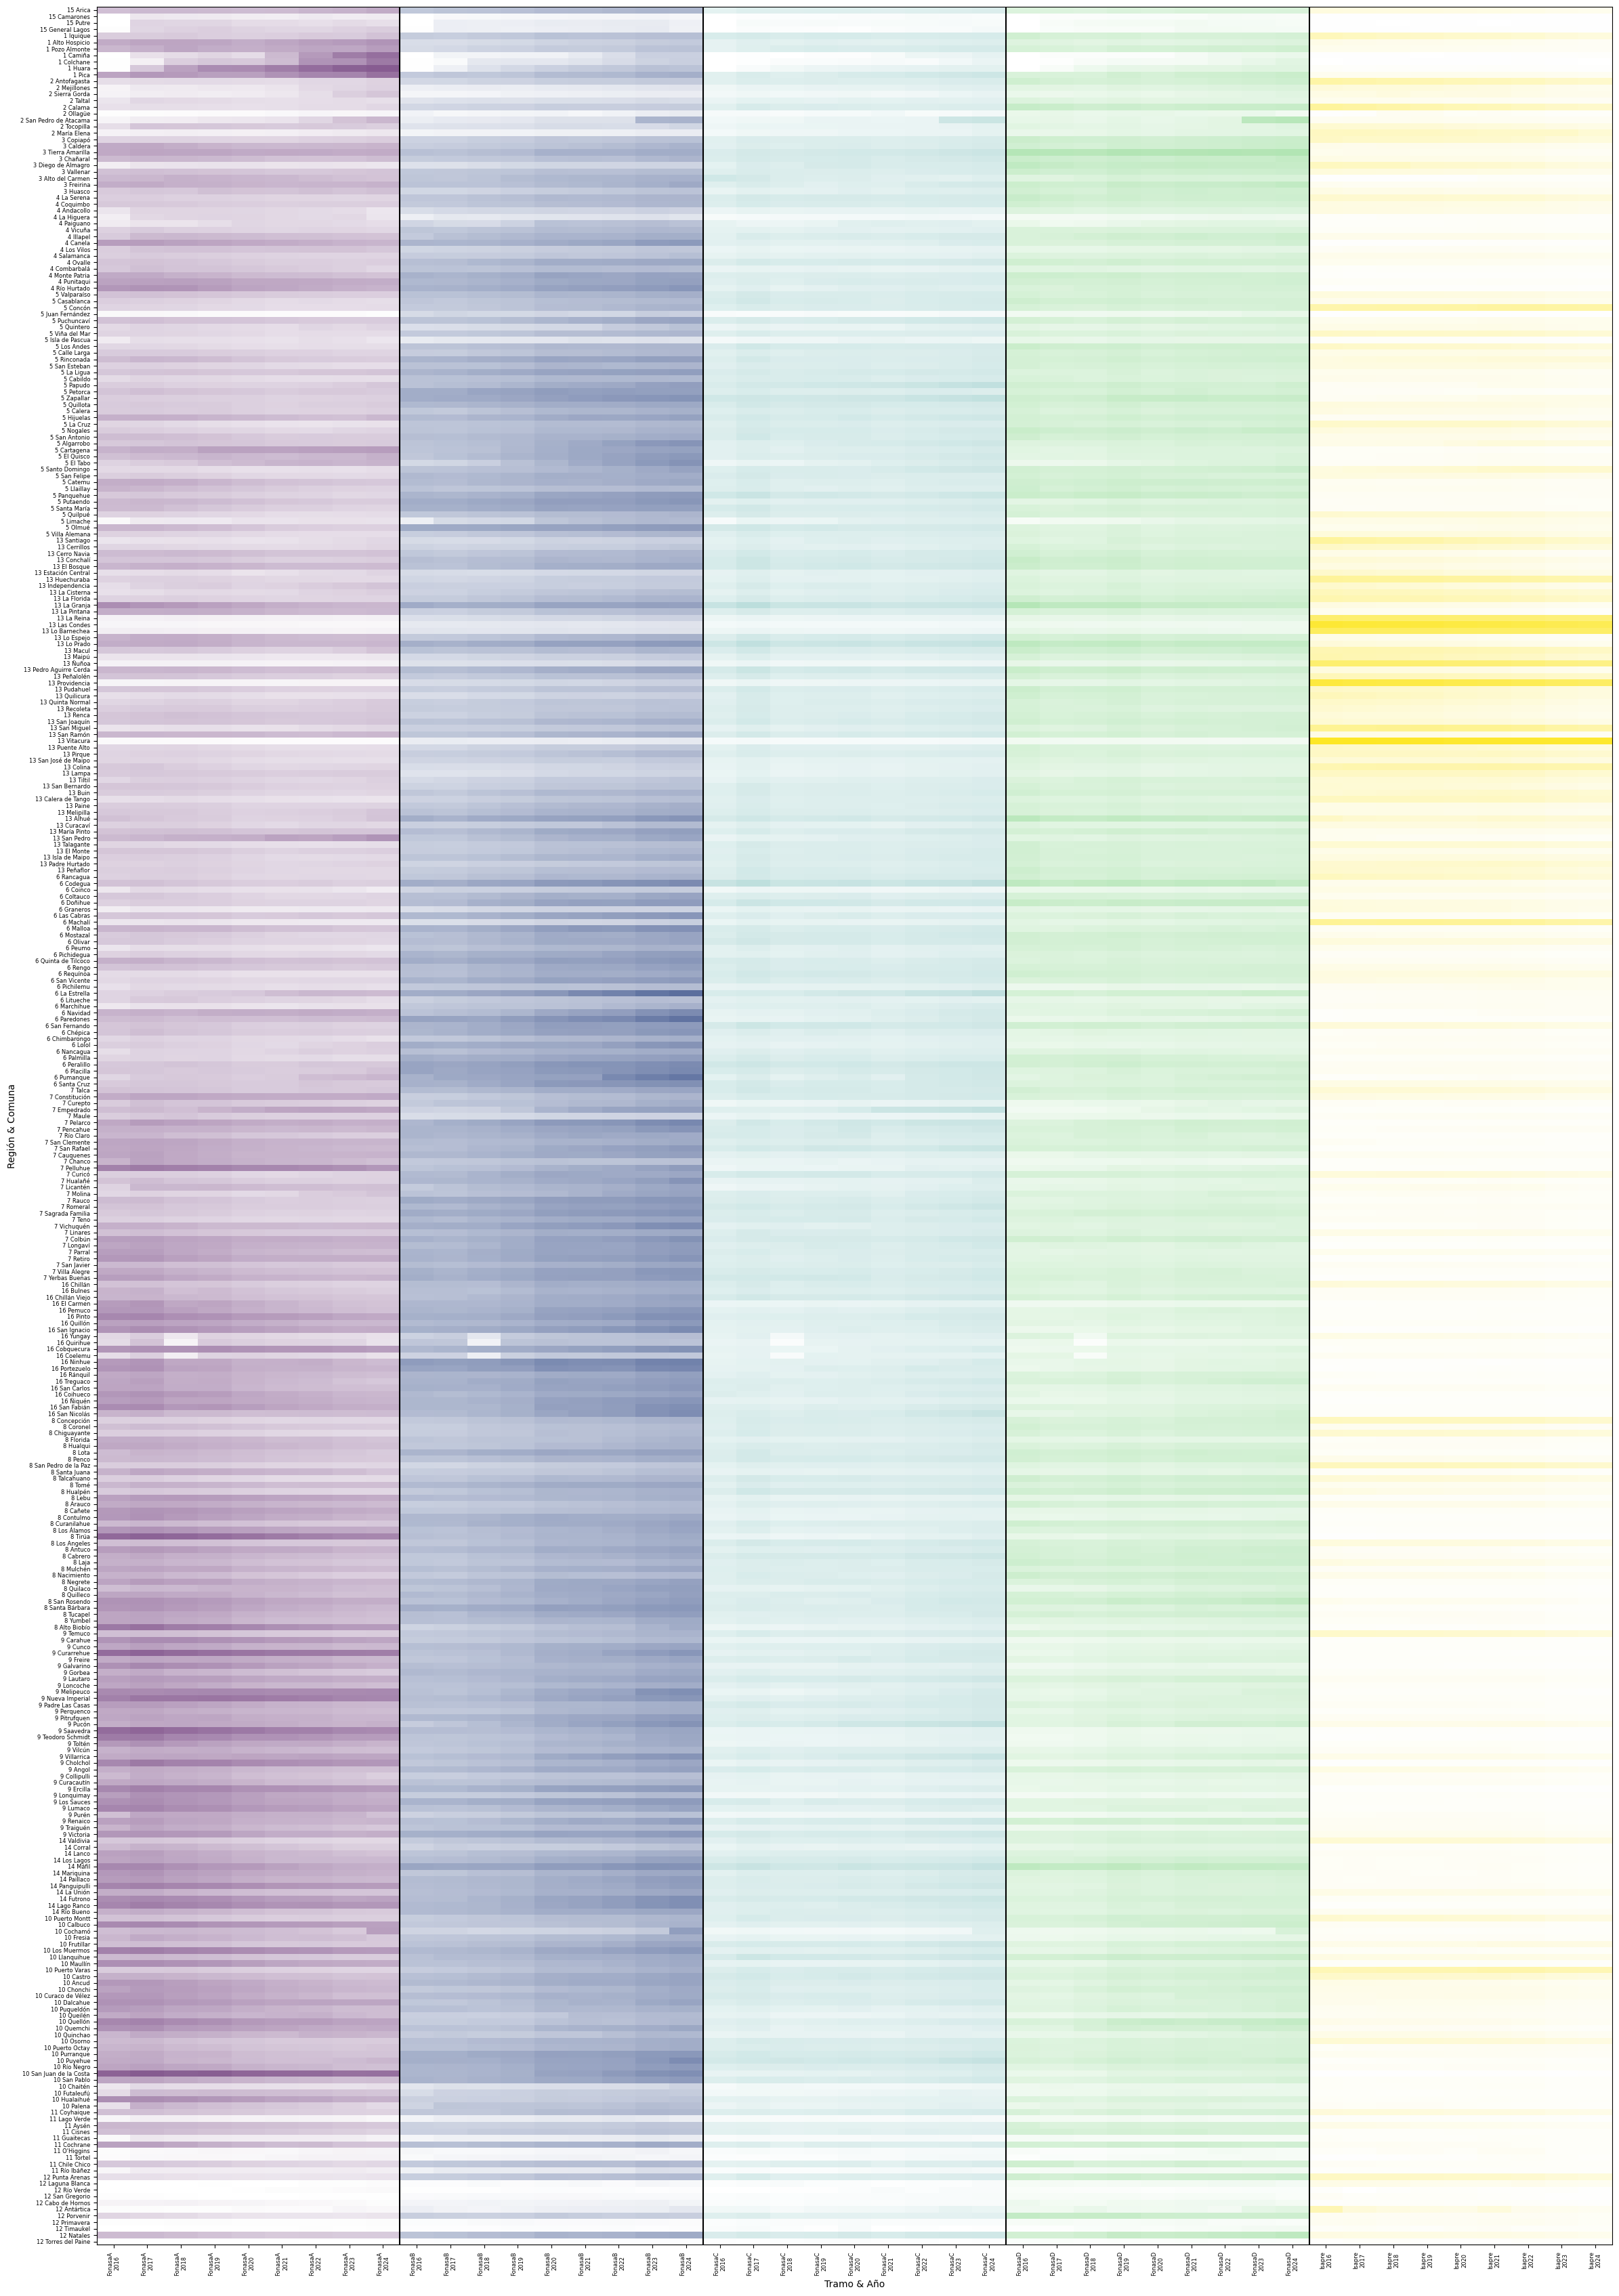

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle

def plot_heatmap_comunas(df):
    # Ensure clean, sorted structures
    tramo_order = ['FonasaA', 'FonasaB', 'FonasaC', 'FonasaD', 'Isapre']
    
    # Group dynamically to compute Cobertura
    df_heat = df.groupby(['ComunaSorted', 'Region', 'Nombre Comuna', 'Tramo', 'Año'])[['Beneficiarios', 'Poblacion']].sum().reset_index()
    df_heat['Cobertura'] = df_heat['Beneficiarios'] / df_heat['Poblacion']
    df_heat['Nombre Region'] = df_heat.Region.astype(str) + ' ' + df_heat['Nombre Comuna']
    
    # Ensure sorted order
    df_heat['Tramo'] = pd.Categorical(df_heat['Tramo'], categories=tramo_order, ordered=True)
    df_heat = df_heat.sort_values(by=['ComunaSorted', 'Tramo', 'Año'])
    
    # Get sorted structures for dimensions
    comuna_sorted_list = sorted(df_heat['ComunaSorted'].unique())
    years_list = sorted(df_heat['Año'].unique())
    
    # Map coordinates
    col_tuples = [(tr, yr) for tr in tramo_order for yr in years_list]
    col_map = {val: j for j, val in enumerate(col_tuples)}
    row_map = {val: i for i, val in enumerate(comuna_sorted_list)}
    
    # Map ComunaSorted to its corresponding Region Name for y-labels
    region_label_map = df_heat.drop_duplicates('ComunaSorted').set_index('ComunaSorted')['Nombre Region'].to_dict()
    y_labels = [region_label_map[c_id] for c_id in comuna_sorted_list]
    
    # Map Tramos to base Viridis colors
    viridis_cmap = plt.get_cmap('viridis')
    tramo_colors = {tramo: viridis_cmap(i / (len(tramo_order) - 1)) for i, tramo in enumerate(tramo_order)}
    
    # Normalize Cobertura for alpha mapping
    min_cob = df_heat['Cobertura'].min()
    max_cob = df_heat['Cobertura'].max()
    span = (max_cob - min_cob) if (max_cob - min_cob) > 0 else 1.0
    df_heat['Alpha'] = (df_heat['Cobertura'] - min_cob) / span
    
    # Dynamic figure height based on rows
    fig_height = max(5, int(len(comuna_sorted_list) * 0.10))
    fig, ax = plt.subplots(figsize=(24, fig_height), dpi=100)
    
    # Render cell rectangles
    for _, row in df_heat.iterrows():
        r_key = row['ComunaSorted']
        c_key = (row['Tramo'], row['Año'])
        
        if r_key in row_map and c_key in col_map:
            y = row_map[r_key]
            x = col_map[c_key]
            base_color = tramo_colors[row['Tramo']]
            alpha_val = float(row['Alpha'])
            rgba_color = (base_color[0], base_color[1], base_color[2], alpha_val)
            
            rect = Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=rgba_color, edgecolor='none')
            ax.add_patch(rect)
            
    # Setup grid limits
    ax.set_xlim(-0.5, len(col_tuples) - 0.5)
    ax.set_ylim(-0.5, len(comuna_sorted_list) - 0.5)
    
    # Setup row labels (Only Region Name)
    ax.set_yticks(np.arange(len(comuna_sorted_list)))
    ax.set_yticklabels(y_labels, fontsize=6)
    
    # Setup column labels
    ax.set_xticks(np.arange(len(col_tuples)))
    ax.set_xticklabels([f"{tr}\n{yr}" for tr, yr in col_tuples], fontsize=6, rotation=90)
    
    # Draw horizontal separator lines between different regions
    '''for i in range(len(y_labels) - 1):
        if y_labels[i] != y_labels[i + 1]:
            ax.axhline(y=i + 0.5, color='white', linewidth=1, linestyle='--')
       '''     
    # Draw vertical separators for Tramo groups
    for i in range(1, len(tramo_order)):
        ax.axvline(x=(i * len(years_list)) - 0.5, color='black', linewidth=1.5, linestyle='-')
        
    ax.invert_yaxis()  # Standard ordering (top region at the top)
    #ax.set_title("Heatmap of Cobertura by Region (Comunas Grouped) vs Tramo & Year", fontsize=14, pad=20)
    ax.set_xlabel("Tramo & Año", fontsize=10)
    ax.set_ylabel("Región & Comuna", fontsize=10)
    
    plt.tight_layout()
    plt.show()

# Generate the heatmap using the custom function
plot_heatmap_comunas(cobs)

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_merged_demographic_heatmap(df, comuna_name):
    # Filter the dataframe for the specified Comuna
    df_filtered = df[df['Nombre Comuna'] == comuna_name].copy()
    if df_filtered.empty:
        print(f"No data found for Comuna: {comuna_name}")
        return

    # Ensure clean structures and ordering
    tramo_order = ['FonasaA', 'FonasaB', 'FonasaC', 'FonasaD', 'Isapre']
    
    # Map Sexo to human-readable names
    df_filtered['Sexo_Name'] = df_filtered['Sexo'].map({1: 'Hombre', 2: 'Mujer'}).fillna(df_filtered['Sexo'])
    
    # Group dynamically by combined demographic keys
    df_heat = df_filtered.groupby(['Sexo_Name', 'RangoEdad10', 'Tramo', 'Año'])[['Beneficiarios', 'Poblacion']].sum().reset_index()
    df_heat['Cobertura'] = df_heat['Beneficiarios'] / df_heat['Poblacion']
    
    # Imprimir resumen
    resumen = (df_heat.groupby(['Tramo','Sexo_Name'])[['Beneficiarios','Poblacion']].sum().reset_index().
               assign(Cobertura=lambda x: x.Beneficiarios/x.Poblacion).
               drop(columns=['Beneficiarios','Poblacion']))
    print(resumen)
    
    # Create a combined demographic y-axis category
    df_heat['Demografico'] = df_heat['Sexo_Name'].astype(str) + " - " + df_heat['RangoEdad10'].astype(str)
    
    # Ensure sorted order
    df_heat['Tramo'] = pd.Categorical(df_heat['Tramo'], categories=tramo_order, ordered=True)
    df_heat = df_heat.sort_values(by=['Sexo_Name', 'RangoEdad10', 'Tramo', 'Año'])
    
    # Unique sorted categories for matrix coordinates
    demograficos_list = sorted(df_heat['Demografico'].unique())
    years_list = sorted(df_heat['Año'].unique())
    
    col_tuples = [(tr, yr) for tr in tramo_order for yr in years_list]
    col_map = {val: j for j, val in enumerate(col_tuples)}
    row_map = {val: i for i, val in enumerate(demograficos_list)}
    
    # Map Tramos to base Viridis colors
    viridis_cmap = plt.get_cmap('viridis')
    tramo_colors = {tramo: viridis_cmap(i / (len(tramo_order) - 1)) for i, tramo in enumerate(tramo_order)}
    
    # Normalize Cobertura for alpha mapping
    min_cob = df_heat['Cobertura'].min()
    max_cob = df_heat['Cobertura'].max()
    span = (max_cob - min_cob) if (max_cob - min_cob) > 0 else 1.0
    df_heat['Alpha'] = (df_heat['Cobertura'] - min_cob) / span
    
    # Define figure size dynamically
    fig_height = max(6, int(len(demograficos_list) * 0.5))
    fig, ax = plt.subplots(figsize=(20, fig_height), dpi=100)
    
    # Render each cell coordinate
    for _, row in df_heat.iterrows():
        r_key = row['Demografico']
        c_key = (row['Tramo'], row['Año'])
        
        if r_key in row_map and c_key in col_map:
            y = row_map[r_key]
            x = col_map[c_key]
            base_color = tramo_colors[row['Tramo']]
            alpha_val = float(row['Alpha'])
            rgba_color = (base_color[0], base_color[1], base_color[2], alpha_val)
            
            rect = Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=rgba_color, edgecolor='none')
            ax.add_patch(rect)
            
    # Setup limits
    ax.set_xlim(-0.5, len(col_tuples) - 0.5)
    ax.set_ylim(-0.5, len(demograficos_list) - 0.5)
    
    # Setup axes labels
    ax.set_yticks(np.arange(len(demograficos_list)))
    ax.set_yticklabels(demograficos_list, fontsize=9)
    
    ax.set_xticks(np.arange(len(col_tuples)))
    ax.set_xticklabels([f"{tr}\n{yr}" for tr, yr in col_tuples], fontsize=7, rotation=90)
    
    # Draw horizontal divider between demographic divisions (Mujer vs Hombre)
    for i in range(len(demograficos_list) - 1):
        label_current = demograficos_list[i].split(" - ")[0]
        label_next = demograficos_list[i + 1].split(" - ")[0]
        if label_current != label_next:
            ax.axhline(y=i + 0.5, color='black', linewidth=1.5, linestyle='--')
            
    # Draw vertical separators for Tramo groups
    for i in range(1, len(tramo_order)):
        ax.axvline(x=(i * len(years_list)) - 0.5, color='black', linewidth=1.5, linestyle='-')
        
    ax.invert_yaxis()  # Put alphabetically top items at the top
    #ax.set_title(f"Heatmap of Cobertura for {comuna_name}: Sexo & RangoEdad10 vs Tramo & Año", fontsize=13, pad=20)
    ax.set_xlabel("Tramo & Año", fontsize=10)
    ax.set_ylabel("Sexo & Rango Etario", fontsize=10)
    
    plt.tight_layout()
    plt.show()


     Tramo Sexo_Name  Cobertura
0  FonasaA    Hombre   0.026888
1  FonasaA     Mujer   0.030645
2  FonasaB    Hombre   0.077716
3  FonasaB     Mujer    0.14872
4  FonasaC    Hombre   0.034594
5  FonasaC     Mujer   0.052418
6  FonasaD    Hombre   0.070755
7  FonasaD     Mujer   0.091788
8   Isapre    Hombre   0.704656
9   Isapre     Mujer   0.707626


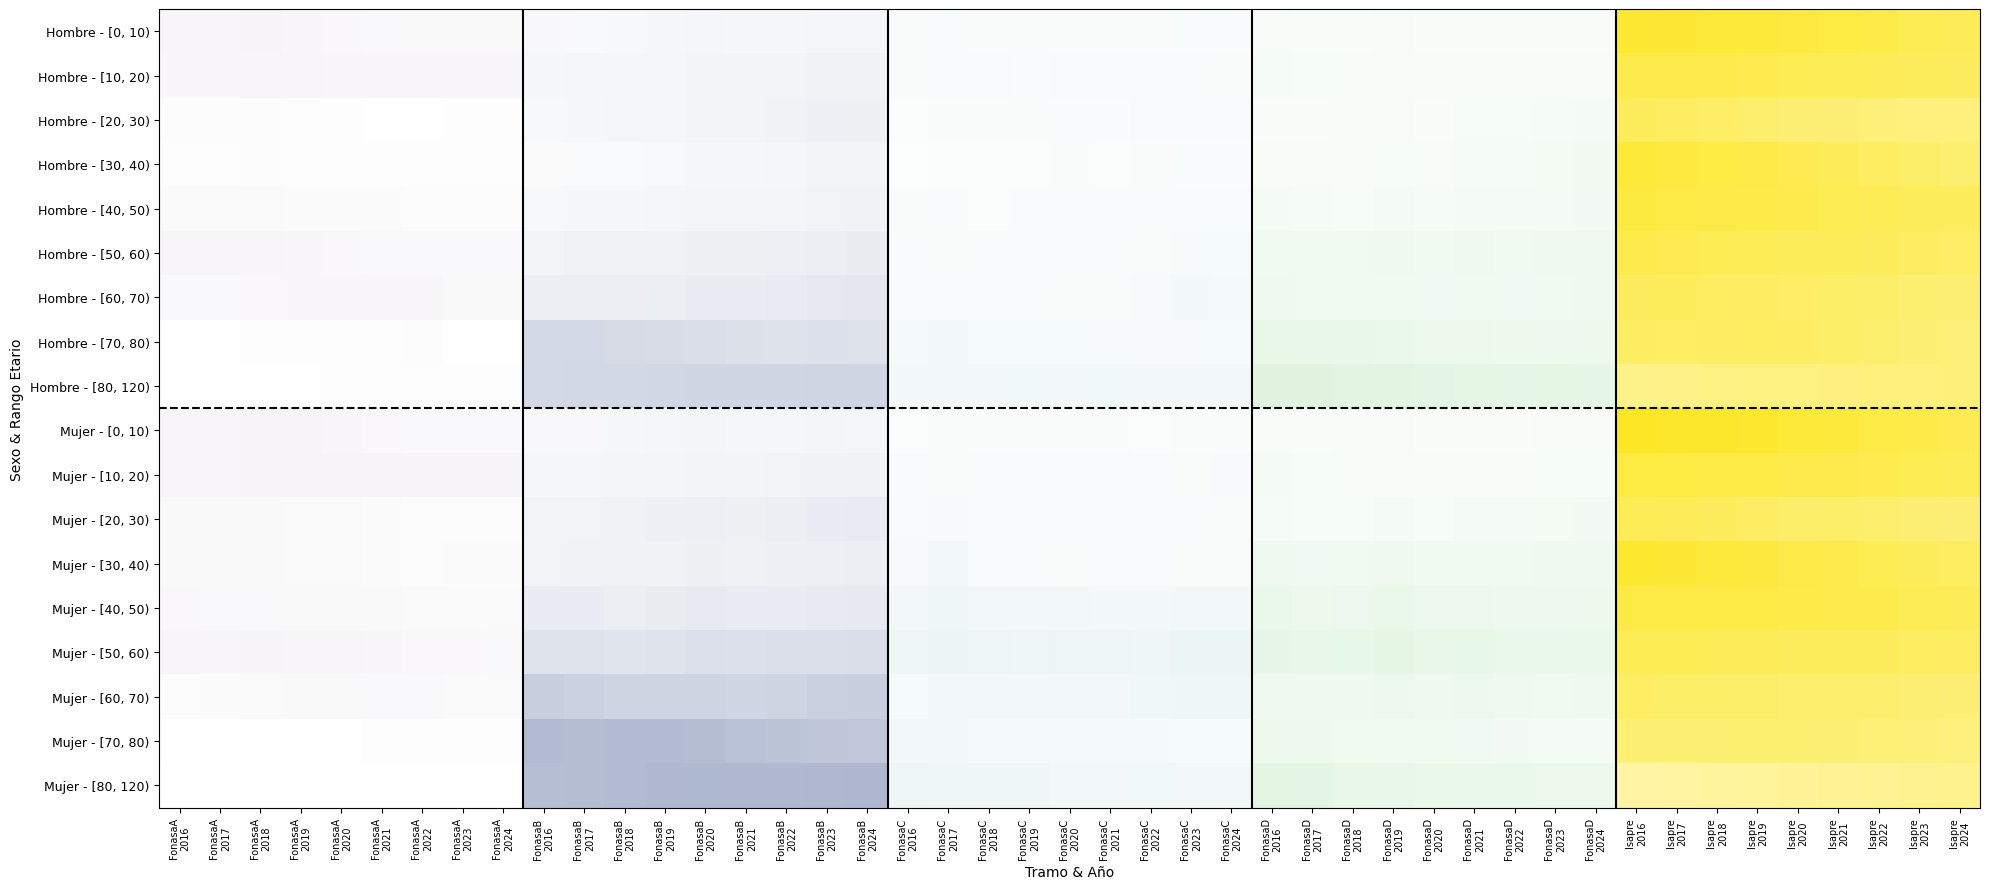

In [9]:
plot_merged_demographic_heatmap(cobs, "Las Condes")

# Las Condes es una de las comunas con mayores ingresos de Chile. La cobertura mayoritariamente Isapre (71% en el periodo de estudio), sin diferencias significativas entre sexos, salvo en Fonasa B, donde la cobertura de mujeres duplica a la de los hombres

     Tramo Sexo_Name  Cobertura
0  FonasaA    Hombre   0.081049
1  FonasaA     Mujer   0.122879
2  FonasaB    Hombre   0.162449
3  FonasaB     Mujer   0.226804
4  FonasaC    Hombre   0.112753
5  FonasaC     Mujer   0.117472
6  FonasaD    Hombre   0.187563
7  FonasaD     Mujer   0.173721
8   Isapre    Hombre   0.306185
9   Isapre     Mujer   0.249217


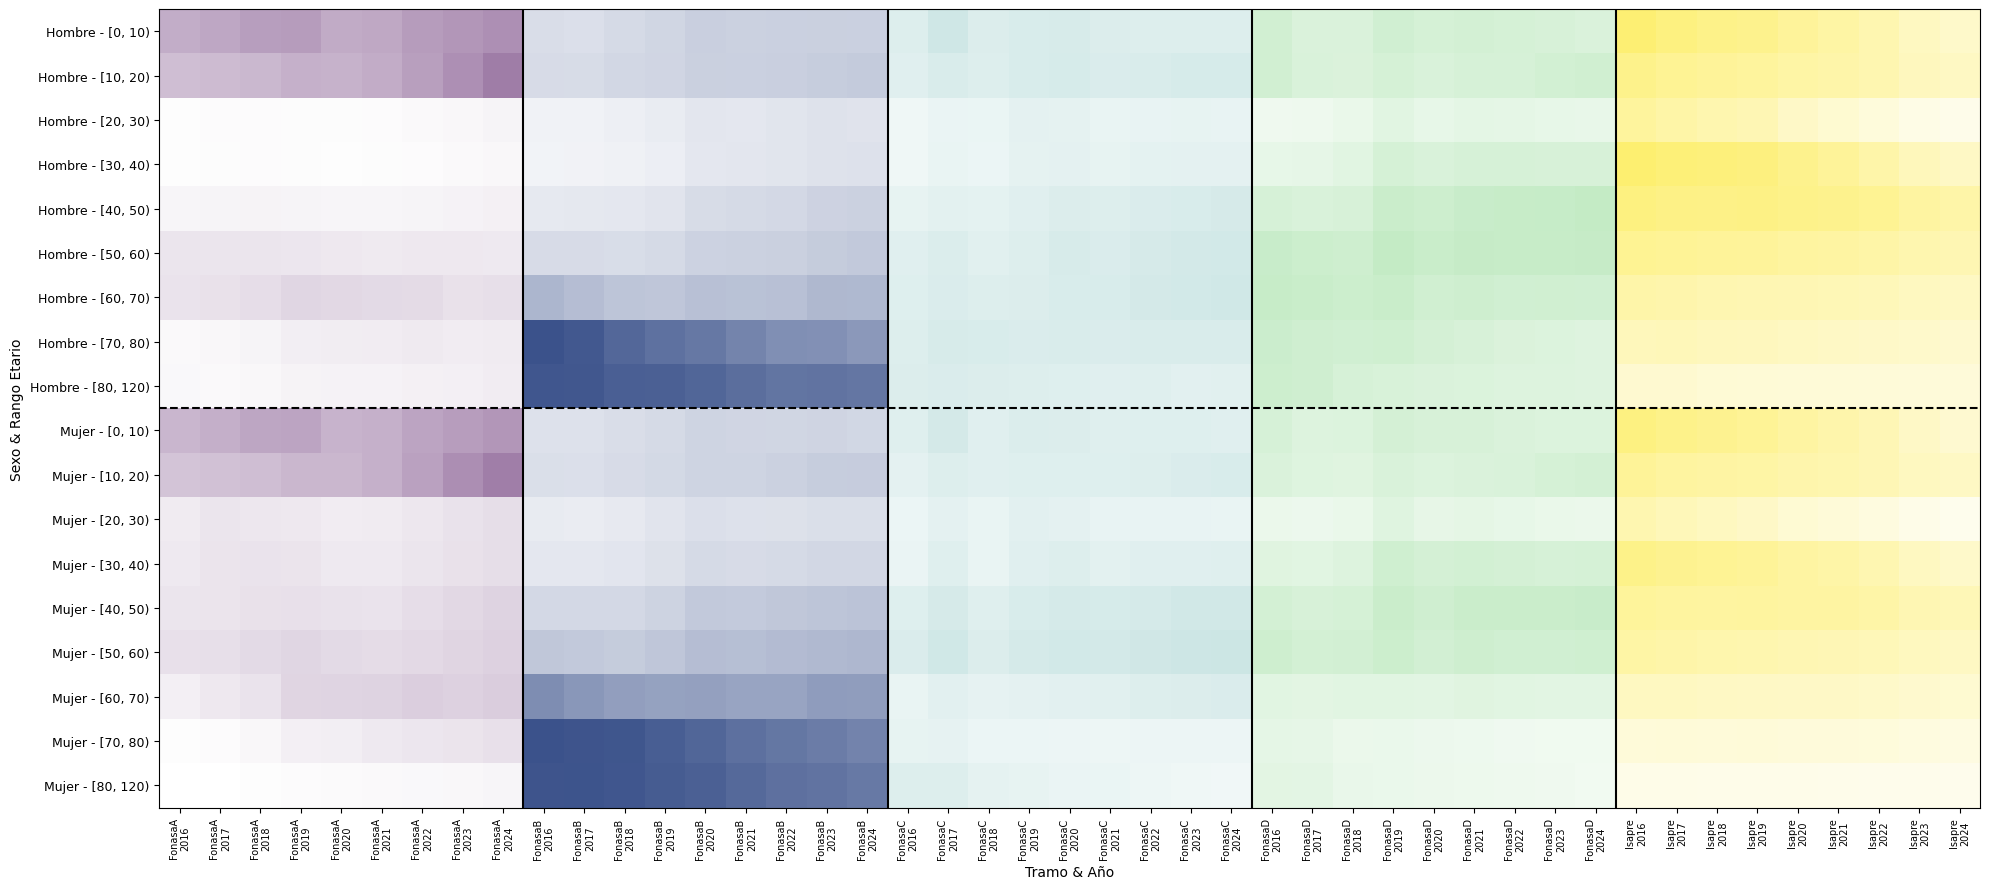

In [10]:
plot_merged_demographic_heatmap(cobs, "Santiago")
# Santiago es la comuna de la capital, con una alta actividad económica. Cobertura isapre es mayoritaria (28%, seguido por Fonasa D con 18%), concentrada en grupos etarios 30 a 60 años, con una disminución a partir de 2020 y aumento de Fonasa D en el mismo periodo.

In [11]:
cobs[(cobs['Nombre Comuna']=='Santiago')&(cobs.RangoEdad10.isin(['[70, 80)','[80, 120)']))].groupby('Tramo').Cobertura.mean()
# La cobertura de Fonasa B es de 64% a partir de los 70 años.

Tramo
FonasaA     0.05263
FonasaB    0.639684
FonasaC    0.109158
FonasaD    0.152291
Isapre     0.148342
Name: Cobertura, dtype: Float64

     Tramo Sexo_Name  Cobertura
0  FonasaA    Hombre   0.096893
1  FonasaA     Mujer   0.148342
2  FonasaB    Hombre   0.175752
3  FonasaB     Mujer   0.272105
4  FonasaC    Hombre   0.120895
5  FonasaC     Mujer   0.133342
6  FonasaD    Hombre   0.249862
7  FonasaD     Mujer   0.197751
8   Isapre    Hombre   0.286697
9   Isapre     Mujer   0.239262


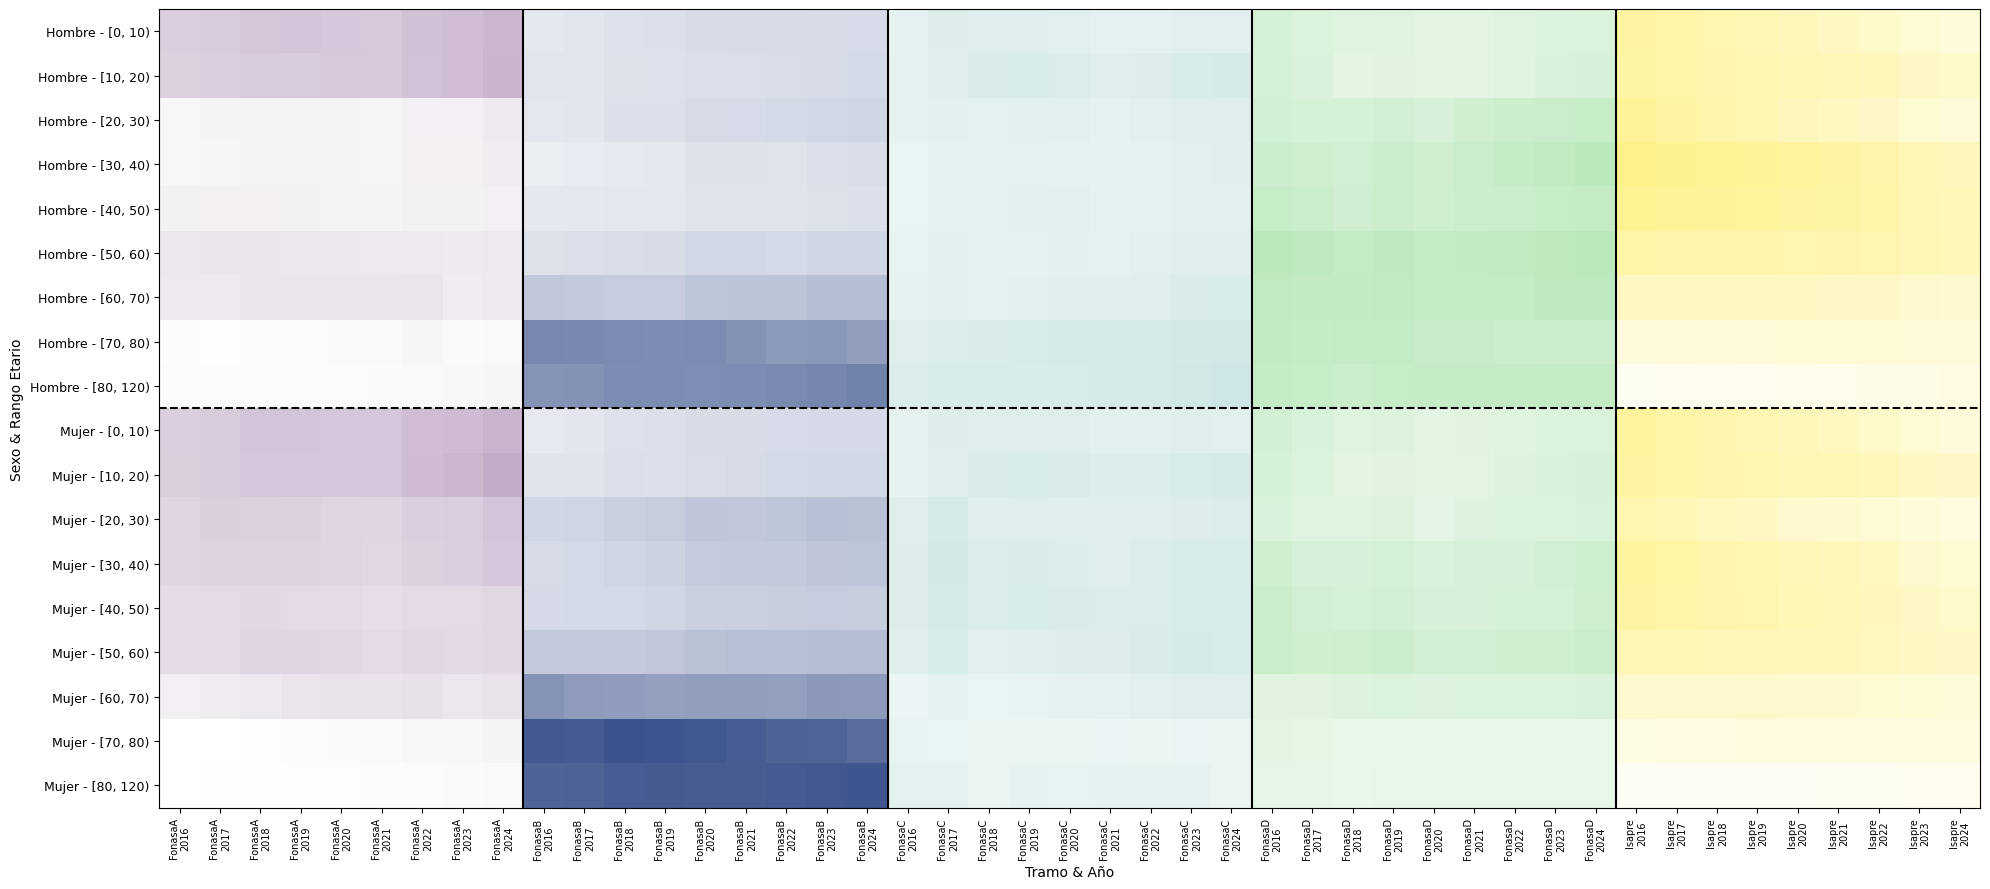

In [12]:
plot_merged_demographic_heatmap(cobs, "Antofagasta")
# Antofagasta es una comuna con una importante actividad minera. Cobertura se concentra en Isapre (25%) y Fonasa D (23%), con una disminución apreciable a partir de 2020.

     Tramo Sexo_Name  Cobertura
0  FonasaA    Hombre   0.110994
1  FonasaA     Mujer    0.15357
2  FonasaB    Hombre   0.254974
3  FonasaB     Mujer   0.365764
4  FonasaC    Hombre   0.148579
5  FonasaC     Mujer   0.134055
6  FonasaD    Hombre   0.270148
7  FonasaD     Mujer   0.194107
8   Isapre    Hombre   0.152907
9   Isapre     Mujer   0.116099


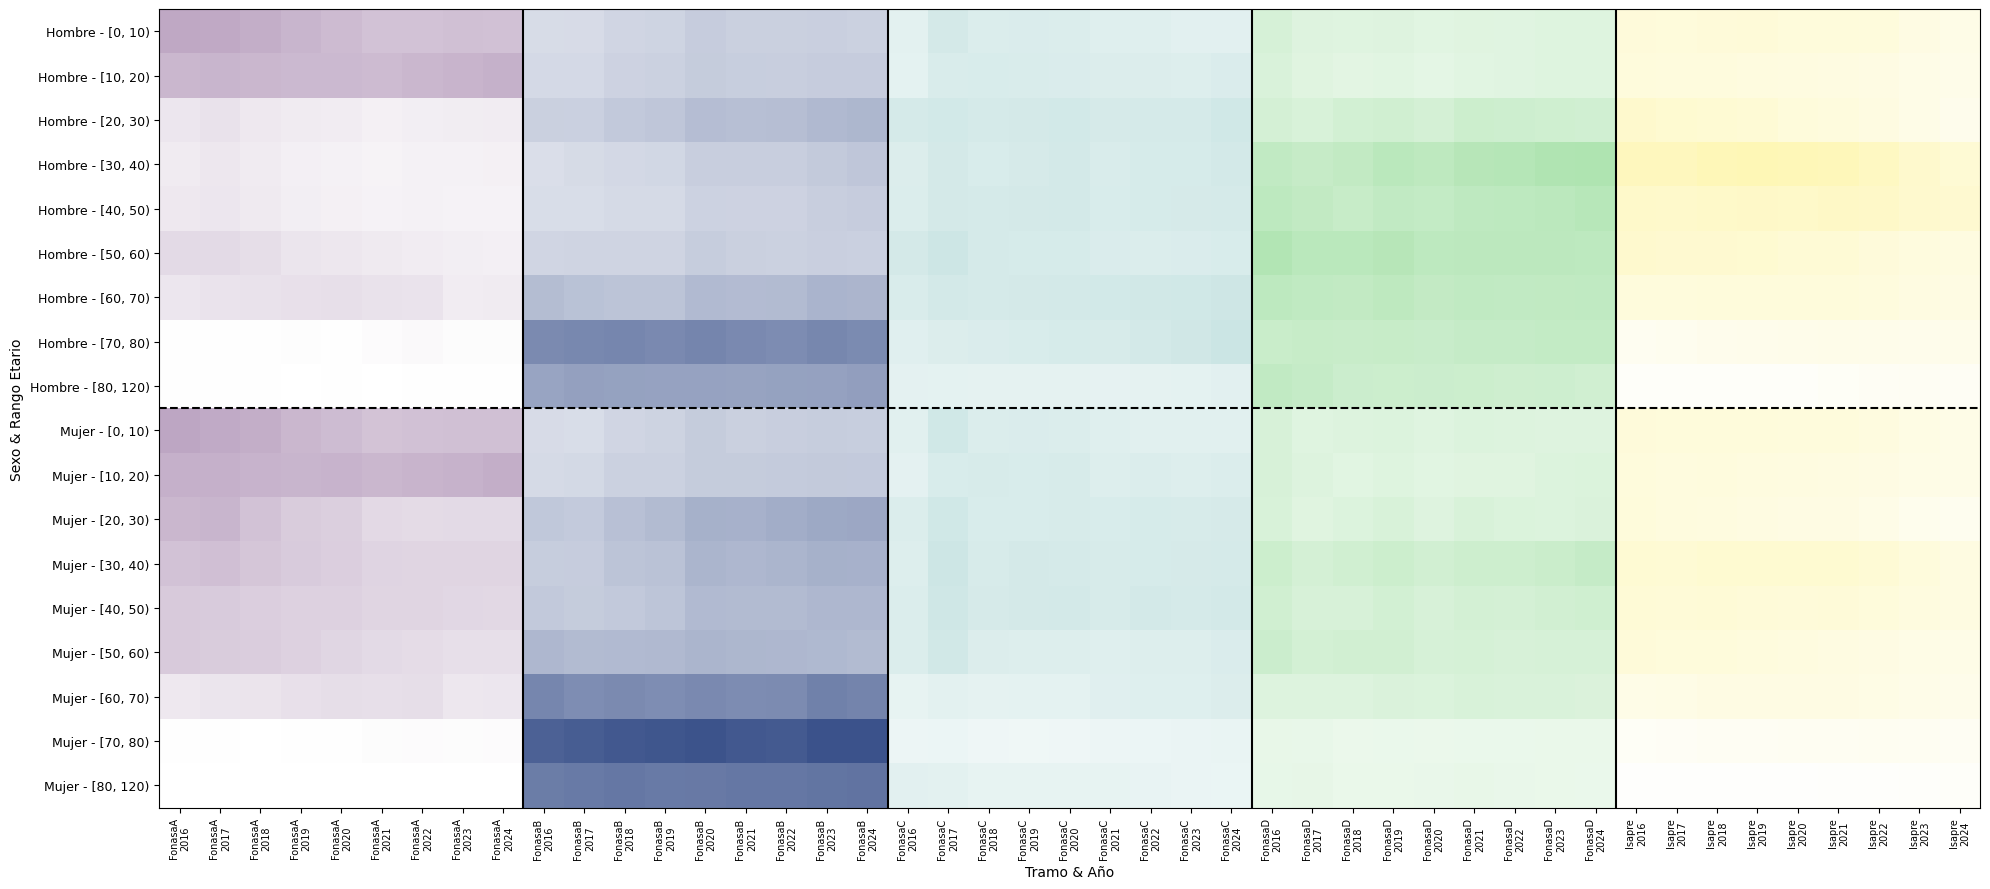

In [13]:
plot_merged_demographic_heatmap(cobs, "Talcahuano")
# Talcahuano es una comuna portuaria, con alta cobertura Fonasa D en hombres (27%) y Fonasa B en mujeres (36%).

     Tramo Sexo_Name  Cobertura
0  FonasaA    Hombre   0.407093
1  FonasaA     Mujer   0.458587
2  FonasaB    Hombre    0.33673
3  FonasaB     Mujer   0.364531
4  FonasaC    Hombre   0.106356
5  FonasaC     Mujer     0.0653
6  FonasaD    Hombre   0.111725
7  FonasaD     Mujer   0.074714
8   Isapre    Hombre   0.011339
9   Isapre     Mujer   0.014036


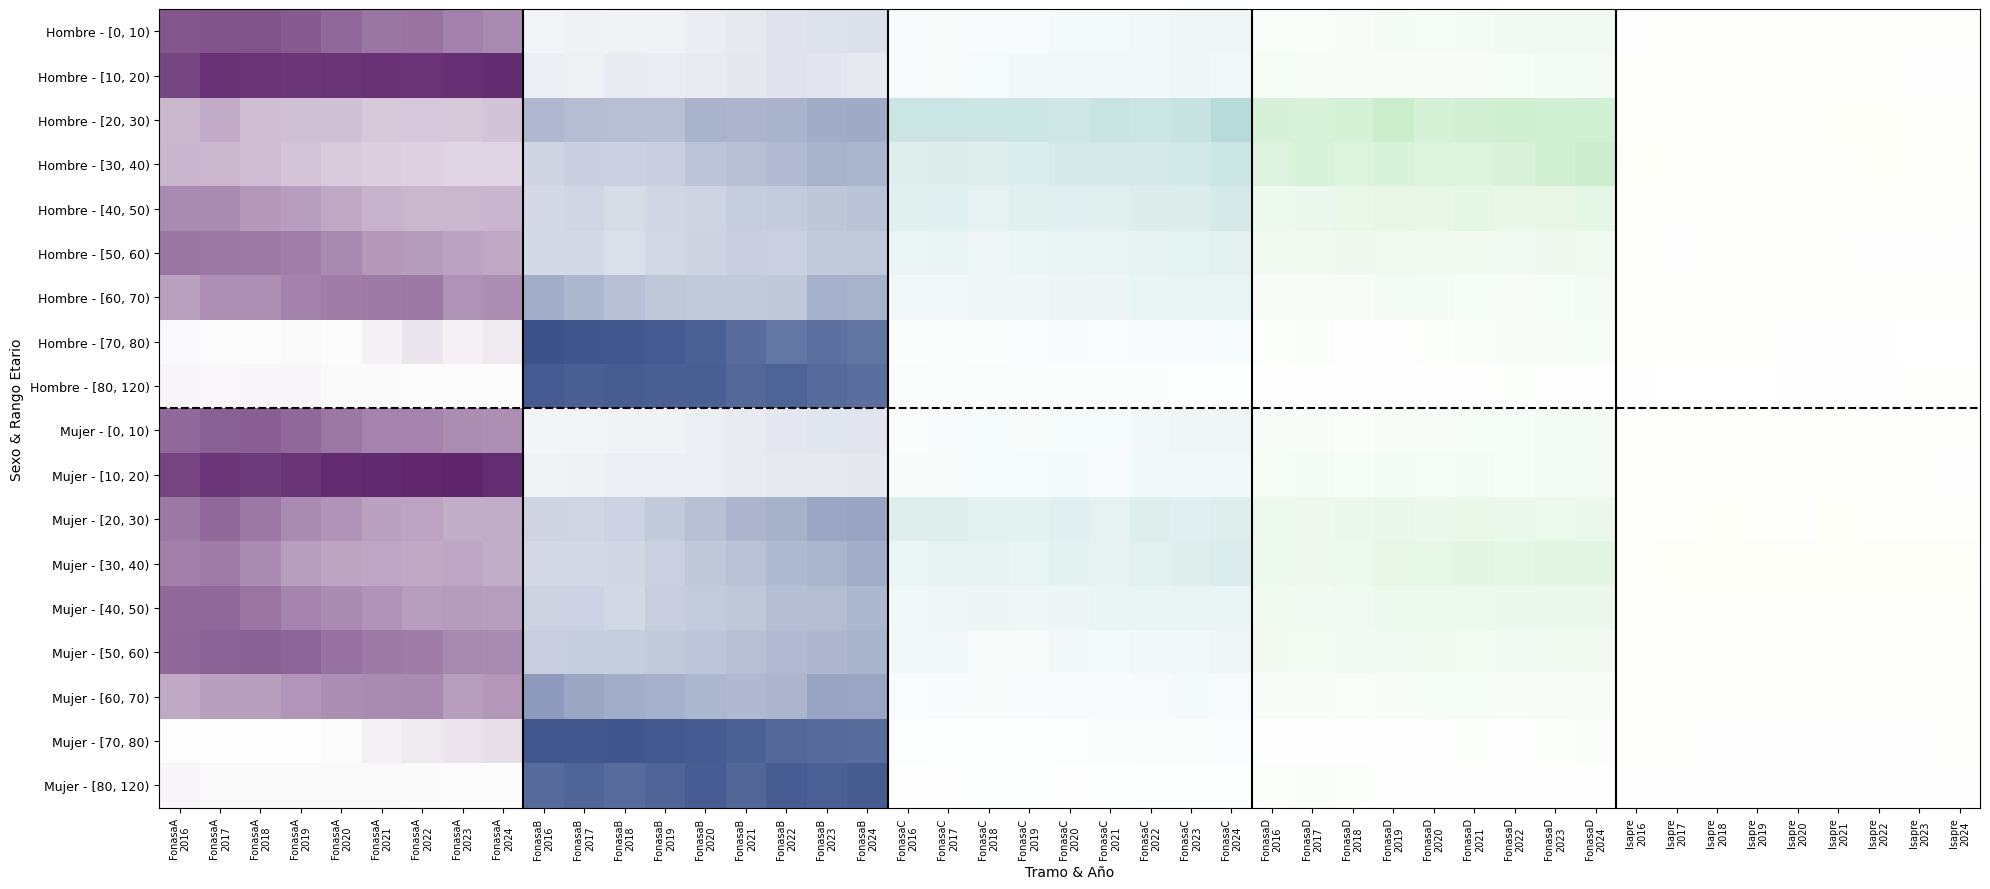

In [14]:
plot_merged_demographic_heatmap(cobs, "Saavedra")
# Saavedra es una comuna rural del sur de Chile con una importante población mapuche, con cobertura concentrada en Fonasa A (43%).